### **Savera Ansari**
### **25k-8009**

# Text Classifier for Sarcasm Detection in Urdu Text
### DS5007 Natural Language Processing, Programming
### Assignment 1





##  Installation

In [39]:
!pip install -q emoji transformers

In [40]:
import os, re, random, json, time, copy, gzip, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import emoji
import scipy.sparse as sp

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

SEED = 42
DATA_PATH = "urdu_sarcastic_dataset.csv"
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

In [41]:
def set_seed(seed=SEED):
    """Fix all random seeds (python, numpy, torch) for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except ImportError:
        pass

set_seed()

##  Load data


In [42]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [43]:
path = "/content/drive/MyDrive/NLP_Sarcasm_Detection/urdu_sarcastic_dataset.csv"

raw_df = pd.read_csv(path, encoding="utf-8-sig")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

print("Dataset shape:", raw_df.shape)
print("Columns:", raw_df.columns.tolist())

display(raw_df.head(10))

Dataset shape: (20060, 2)
Columns: ['urdu_text', 'is_sarcastic']


,urdu_text,is_sarcastic
0,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,1.0
1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,1.0
2,کامران خان آپکی دن بھریہ زمہ داری لگائی گئی اپوزیشن کی کردار کشی اوراس پربھونکناہےآپ خوشامدگری وچاپلوسی سےاورکتنی دولت کماناچاہتےہیں موٹرسائیکل سےپیجارو پراڈو تک کےسفرمیں ضمیرکی لاش سےاٹھتی بدبوآپ کی ناک بند نہیں کرتی ہے 🙏نوٹ آپ سب سےالتجاگزارش ہےہمیں بھی فالوکریں شکریہ,0.0
3,نہیں پائین 😎,0.0
4,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی تھے '' حامد میر😁,1.0
5,قابل اعتبار ہی اکثر قاتل اعتبار ہوتے ہیں 💔🔥,1.0
6,انساں کو تھکا دیتا ہے سوچوں کا سفر بھی ... 🍁🥀,0.0
7,حامد میر صاحب ویلڈن👏😊,0.0
8,یار وچارہ ویلا ہوندا ہے اس آرے لگا ہویا ہے😂😂 تسی تے پکے نجومی ہو اسی منندے ہاں,1.0
9,یہ سمجھتے ہیں سارا پاکستان بیوقوف ھے 😂😂😂,1.0


In [44]:
raw_df.columns = raw_df.columns.astype(str).str.strip().str.lstrip("\ufeff")

display(raw_df.head())

,urdu_text,is_sarcastic
0,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,1.0
1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,1.0
2,کامران خان آپکی دن بھریہ زمہ داری لگائی گئی اپوزیشن کی کردار کشی اوراس پربھونکناہےآپ خوشامدگری وچاپلوسی سےاورکتنی دولت کماناچاہتےہیں موٹرسائیکل سےپیجارو پراڈو تک کےسفرمیں ضمیرکی لاش سےاٹھتی بدبوآپ کی ناک بند نہیں کرتی ہے 🙏نوٹ آپ سب سےالتجاگزارش ہےہمیں بھی فالوکریں شکریہ,0.0
3,نہیں پائین 😎,0.0
4,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی تھے '' حامد میر😁,1.0


##  Exploratory Analysis

missing values, the extra "Unnamed" columns, label balance, exact duplicates, duplicate texts with **different** labels, text length, and surface cues (emojis, hashtags, URLs, Roman script, elongation). The surface cue table tells us which things we must **not** blindly delete during preprocessing.


In [45]:
URL_RE      = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE  = re.compile(r"@\w+")
HASHTAG_RE  = re.compile(r"#(\w+)")
LATIN_RE    = re.compile(r"[A-Za-z]")
ELONG_RE    = re.compile(r"(\w)\1{2,}")
LAUGH_RE    = re.compile(r"(?:ہا|ھا|ha|Ha|HA){2,}")

LEAKY_TAG_RE = re.compile(
    r"#?\b(?:sarcas\w*|satir\w*|iron(?:y|ic)\w*|funny|fun|memes?\w*|jokes?|humou?r\w*|comedy)\b"
    r"|#?(?:طنز\w*|مزاح\w*)",
    flags=re.IGNORECASE)

LAUGH_EMOJIS = set("😂🤣😆😅😁😄😃😹")
MOCK_EMOJIS  = set("😜😝😛🙄😏🤭🤪😒🤔🙃😉😎🤡👏")
POS_EMOJIS   = set("😍❤♥💕💖💗💓💞😊☺🥰😘👍🙏💐🌹🌺🌸✨💯🤲😇💚💙💛🌷")
NEG_EMOJIS   = set("😢😭💔😡😠😔😞😩😤😫😥😰😣🥺😓🤬👎😪")

In [46]:
def get_emojis(text):
    """Return the list of emojis in a text, in order."""
    return [e["emoji"] for e in emoji.emoji_list(str(text))]

In [47]:
def data_quality_report(df):
    """Print missing values, junk columns, label balance, duplicates and conflicts."""
    print("Shape:", df.shape)
    print("\nNon null values per column:")
    print(df.notna().sum().to_string())

    junk = [c for c in df.columns if c not in ("urdu_text", "is_sarcastic")]
    junk_rows = df[junk].notna().any(axis=1).sum()
    print(f"\nRows with values in junk columns {junk}: {junk_rows}")

    print("\nLabel distribution (including missing):")
    print(df["is_sarcastic"].value_counts(dropna=False).to_string())

    d = df.dropna(subset=["urdu_text", "is_sarcastic"]).copy()
    d["key"] = d["urdu_text"].astype(str).str.split().str.join(" ")
    print(f"\nExact duplicate rows (text + label): {d.duplicated(['key', 'is_sarcastic']).sum()}")
    print(f"Duplicate texts (any label):         {d['key'].duplicated().sum()}")
    print(f"Unique texts:                        {d['key'].nunique()}")
    n_labels = d.groupby("key")["is_sarcastic"].nunique()
    print(f"Texts that appear with BOTH labels:  {(n_labels > 1).sum()}")

In [48]:
data_quality_report(raw_df)

Shape: (20060, 2)

Non null values per column:
urdu_text       19955
is_sarcastic    20004

Rows with values in junk columns []: 0

Label distribution (including missing):
is_sarcastic
1.0    10003
0.0    10001
NaN       56

Exact duplicate rows (text + label): 4096
Duplicate texts (any label):         4742
Unique texts:                        15213
Texts that appear with BOTH labels:  646


In [49]:
def show_junk_rows(df, n=5):
    """Show rows where the extra columns contain text (CSV parsing noise)."""
    junk = [c for c in df.columns if c not in ("urdu_text", "is_sarcastic")]
    return df[df[junk].notna().any(axis=1)].head(n)

show_junk_rows(raw_df)

,urdu_text,is_sarcastic


In [50]:
def text_length_stats(df):
    """Character and word length statistics per class, plus histograms."""
    d = df.dropna(subset=["urdu_text", "is_sarcastic"]).copy()
    d["chars"] = d["urdu_text"].astype(str).str.len()
    d["words"] = d["urdu_text"].astype(str).str.split().str.len()
    print(d.groupby("is_sarcastic")[["chars", "words"]].describe().round(1).T)

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for lab, name in [(0, "non sarcastic"), (1, "sarcastic")]:
        ax[0].hist(d.loc[d.is_sarcastic == lab, "chars"], bins=50, alpha=.6, label=name)
        ax[1].hist(d.loc[d.is_sarcastic == lab, "words"], bins=50, alpha=.6, label=name)
    ax[0].set_title("Characters per post"); ax[1].set_title("Words per post")
    ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

is_sarcastic     0.0     1.0
chars count   9993.0  9962.0
      mean      74.1   107.7
      std       59.0    57.9
      min        2.0     5.0
      25%       31.0    67.0
      50%       60.0    97.0
      75%       98.0   129.0
      max      327.0   304.0
words count   9993.0  9962.0
      mean      16.1    23.1
      std       12.4    12.2
      min        1.0     1.0
      25%        7.0    15.0
      50%       13.0    21.0
      75%       21.0    28.0
      max       70.0    71.0


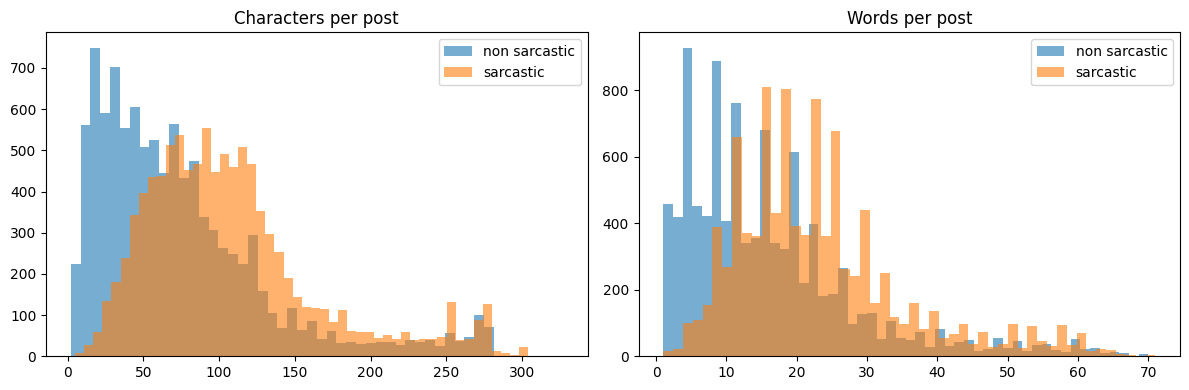

In [51]:
text_length_stats(raw_df)

In [52]:
def surface_cue_table(df):
    """Share of posts in each class that contain a given surface cue."""
    d = df.dropna(subset=["urdu_text", "is_sarcastic"]).copy()
    t = d["urdu_text"].astype(str)
    cues = pd.DataFrame({
        "has_emoji":        t.map(lambda s: len(get_emojis(s)) > 0),
        "laughing_emoji":   t.map(lambda s: any(e in LAUGH_EMOJIS for e in get_emojis(s))),
        "mocking_emoji":    t.map(lambda s: any(e in MOCK_EMOJIS for e in get_emojis(s))),
        "sad_angry_emoji":  t.map(lambda s: any(e in NEG_EMOJIS for e in get_emojis(s))),
        "hashtag":          t.str.contains(HASHTAG_RE),
        "LEAKY_tag":        t.str.contains(LEAKY_TAG_RE),
        "mention":          t.str.contains(MENTION_RE),
        "url":              t.str.contains(URL_RE),
        "roman/english":    t.str.contains(LATIN_RE),
        "elongation":       t.str.contains(ELONG_RE),
        "laughter_text":    t.str.contains(LAUGH_RE),
        "question_mark":    t.str.contains(r"[?؟]"),
        "exclamation":      t.str.contains("!"),
    })
    cues["label"] = d["is_sarcastic"].values
    table = (cues.groupby("label").mean() * 100).T.round(1)
    table.columns = ["% non sarcastic", "% sarcastic"]
    table["ratio (sarc / non)"] = (table["% sarcastic"] / table["% non sarcastic"]).round(2)
    return table.sort_values("ratio (sarc / non)", ascending=False)

In [53]:
cue_table = surface_cue_table(raw_df)
cue_table

,% non sarcastic,% sarcastic,ratio (sarc / non)
LEAKY_tag,0.1,10.1,101.00
hashtag,0.3,7.3,24.33
url,0.3,3.5,11.67
exclamation,0.1,1.0,10.00
mention,0.8,6.9,8.62
roman/english,7.7,20.3,2.64
question_mark,3.7,6.0,1.62
mocking_emoji,12.1,19.5,1.61
laughing_emoji,30.0,44.1,1.47
laughter_text,1.1,1.3,1.18


**Table Readings**

The table compares the frequency of emojis, hashtags, punctuation, and other linguistic cues across sarcastic and non-sarcastic posts. A ratio above 1 indicates that a cue is more common in sarcastic posts, while a ratio below 1 indicates that it is more common in non-sarcastic posts.

These features may provide useful classification signals, but their contribution must be verified through ablation experiments. Explicit sarcasm-related hashtags are treated separately because they may cause label leakage..

In [54]:
def top_emojis_by_class(df, k=15):
    """Most frequent emojis in each class."""
    d = df.dropna(subset=["urdu_text", "is_sarcastic"])
    out = {}
    for lab in (0, 1):
        cnt = Counter(e for s in d.loc[d.is_sarcastic == lab, "urdu_text"] for e in get_emojis(s))
        out[f"label {lab}"] = [f"{e} {n}" for e, n in cnt.most_common(k)]
    return pd.DataFrame(out)

top_emojis_by_class(raw_df)

,label 0,label 1
0,😂 5089,😂 6288
1,🤣 653,😜 1133
2,😜 603,😁 978
3,❤ 528,🤣 961
4,💔 527,😝 660
5,❤️ 495,😅 499
6,🌹 487,😆 413
7,😁 470,😀 397
8,😍 459,😉 301
9,🙏 431,😄 290


In [55]:
def show_examples(df, n=5, seed=SEED):
    """Print random examples from each class."""
    d = df.dropna(subset=["urdu_text", "is_sarcastic"])
    for lab in (0, 1):
        print(f"\n===== label {int(lab)} =====")
        for s in d[d.is_sarcastic == lab].sample(n, random_state=seed)["urdu_text"]:
            print(" *", s[:160].replace("\n", " "))

show_examples(raw_df)


===== label 0 =====
 * اُسی ریاست کے اوپر والی ریاست نے نواز شریف کو کراچی جلسے میں تقریر نہ کرنے دی ۔۔ ظالم 😂
 * کر لے مقابلہ، وہ بھی میں ہی جیتنا۔۔😎😎
 *  محترم باجوہ صاحب نے چال چل دی ہے اب انشاءاللہ مودی اور نیتن یاہو جنرل باجوہ صاحب کے بیٹ مین مقرر ہوں گے😂😂💖💖
 * دیکھتے ہیں ہم نے کافی مقدار میں پاپ کارن منگوا لیے ہیں.. 😂
 *  سنو کہا سے ہو😊 پتہ تو چلے ہم کتنے دور ہیں آپ سے 😅 ☺ Me Lahore

===== label 1 =====
 * بالکل بالکل۔ پی ڈی ایم نے کہا تھا کہ ایسی غلیظ اور اخلاق سے گری ہوئی حرکت کرو۔ ایک آئی جی کو اغواء کرو۔ پرچہ کٹواو اور قوم کی بیٹی کے کمرے میں دروازہ توڑ کر گھس
 * زرداری کو مکار اور بزدل کہنا درست نہیں 😋😋
 * کل تک پاک فوج کو گالیاں دے رہے تھے اور آج PDM پاک فوج سے انکوائری کی سفارش کر رہی ہے اسے کہتے ہیں تھوک کر چاٹنا
 * میری فلاسفی کو کھلے عام ڈرامہ بولا جا رہا ہے،، اس کا بھی نوٹس لیا جائے مائی لارڈ😣😣
 * کل وزیر داخلہ برگیڈیئر اعجاز شاہ سے سلیم صافی نے پوچھا ماضی میں عمران خان کے اداروں کے حوالے سے موجود اپوزیشن کے برعکس سخت بیانات موجود ہیں تو اس جواب میں اعجاز


**EDA Verification**

In [184]:


eda_df = raw_df.dropna(
    subset=["urdu_text", "is_sarcastic"]
).copy()

eda_df["is_sarcastic"] = pd.to_numeric(
    eda_df["is_sarcastic"], errors="coerce"
)

eda_df = eda_df[
    eda_df["is_sarcastic"].isin([0, 1])
]

print("Total loaded rows:", len(raw_df))
print("Valid rows for EDA:", len(eda_df))

print("\nClass distribution:")
print(eda_df["is_sarcastic"].value_counts().sort_index())

print("\nClass distribution (%):")
print(
    eda_df["is_sarcastic"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nEmoji statistics:")
display(surface_cue_table(eda_df))

Total loaded rows: 20060
Valid rows for EDA: 19955

Class distribution:
is_sarcastic
0.0    9993
1.0    9962
Name: count, dtype: int64

Class distribution (%):
is_sarcastic
0.0    50.08
1.0    49.92
Name: proportion, dtype: float64

Emoji statistics:


,% non sarcastic,% sarcastic,ratio (sarc / non)
LEAKY_tag,0.1,6.6,66.00
hashtag,0.3,7.3,24.33
url,0.3,3.5,11.67
exclamation,0.1,1.0,10.00
mention,0.8,6.9,8.62
roman/english,7.7,20.3,2.64
question_mark,3.7,6.0,1.62
mocking_emoji,12.1,19.5,1.61
laughing_emoji,30.0,44.1,1.47
laughter_text,1.1,1.3,1.18


## Cleaning

Remove missing values, empty text, and leaky label tags while preserving the original text. Deduplicate tweets, resolve conflicting labels by majority vote, drop ties, and retain soft labels for transformer training.

In [57]:
import unicodedata

In [58]:
LEAKY_TAG_RE = re.compile(
    r"(?<!\w)#?\s*(?:"
    r"sarcasm|sarcastic|sarcastically|"
    r"notsarcastic|nonsarcastic|non_sarcastic|"
    r"satire|طنز|طنزیہ"
    r")(?!\w)",
    flags=re.IGNORECASE
)

In [59]:
def normalize_whitespace(text):
    """Normalize whitespace without changing Urdu words."""
    return re.sub(r"\s+", " ", str(text)).strip()

In [60]:
def remove_leaky_tags(text):
    """Remove explicit sarcasm label tags while preserving other text."""
    text = LEAKY_TAG_RE.sub(" ", str(text))
    return normalize_whitespace(text)

In [61]:
def validate_dataset(df):
    """Validate required columns, labels and non-empty text."""

    required = ["urdu_text", "is_sarcastic"]

    missing = set(required) - set(df.columns)

    if missing:
        raise ValueError(f"Missing columns: {missing}")

    d = df[required].copy()

    initial_rows = len(d)

    # Preserve original text
    d["text_with_tags"] = d["urdu_text"]

    # Convert labels safely
    d["is_sarcastic"] = pd.to_numeric(
        d["is_sarcastic"],
        errors="coerce"
    )

    # Remove missing text and labels
    d = d.dropna(subset=required)

    # Accept only binary labels
    d = d[d["is_sarcastic"].isin([0, 1])].copy()

    d["is_sarcastic"] = d["is_sarcastic"].astype(int)

    # Normalize whitespace
    d["urdu_text"] = d["urdu_text"].map(normalize_whitespace)

    # Remove empty text
    d = d[d["urdu_text"].str.len() > 0].copy()

    print("Initial rows:", initial_rows)
    print("Valid rows:", len(d))
    print("Removed rows:", initial_rows - len(d))

    return d.reset_index(drop=True)

In [62]:
def clean_text(df):
    """Remove label leakage and create cleaned text column."""

    d = df.copy()

    d["text"] = d["urdu_text"].map(remove_leaky_tags)

    d = d[d["text"].str.len() > 0].copy()

    return d.reset_index(drop=True)

In [63]:
def remove_meaningless_rows(df):
    """Remove text without meaningful linguistic or emoji content."""

    d = df.copy()

    def is_meaningful(text):
        text = str(text).strip()

        if not text:
            return False

        if re.search(r"[\u0600-\u06FFa-zA-Z]", text):
            return True

        if any(
            ord(char) >= 0x1F000
            for char in text
        ):
            return True

        return False

    before = len(d)

    d = d[d["text"].map(is_meaningful)].copy()

    print("Meaningless rows removed:", before - len(d))

    return d.reset_index(drop=True)

In [64]:
validated_df = validate_dataset(raw_df)

print("\nPosts containing leaky tags:",
      validated_df["text_with_tags"]
      .astype(str)
      .str.contains(LEAKY_TAG_RE, na=False)
      .sum())

clean_df = clean_text(validated_df)

clean_df = remove_meaningless_rows(clean_df)

print("\nRows after cleaning:", len(clean_df))

display(
    clean_df[
        ["text_with_tags", "text", "is_sarcastic"]
    ].head(10)
)

Initial rows: 20060
Valid rows: 19955
Removed rows: 105

Posts containing leaky tags: 667
Meaningless rows removed: 3

Rows after cleaning: 19952


,text_with_tags,text,is_sarcastic
0,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,1
1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,1
2,کامران خان آپکی دن بھریہ زمہ داری لگائی گئی اپوزیشن کی کردار کشی اوراس پربھونکناہےآپ خوشامدگری وچاپلوسی سےاورکتنی دولت کماناچاہتےہیں موٹرسائیکل سےپیجارو پراڈو تک کےسفرمیں ضمیرکی لاش سےاٹھتی بدبوآپ کی ناک بند نہیں کرتی ہے 🙏نوٹ آپ سب سےالتجاگزارش ہےہمیں بھی فالوکریں شکریہ,کامران خان آپکی دن بھریہ زمہ داری لگائی گئی اپوزیشن کی کردار کشی اوراس پربھونکناہےآپ خوشامدگری وچاپلوسی سےاورکتنی دولت کماناچاہتےہیں موٹرسائیکل سےپیجارو پراڈو تک کےسفرمیں ضمیرکی لاش سےاٹھتی بدبوآپ کی ناک بند نہیں کرتی ہے 🙏نوٹ آپ سب سےالتجاگزارش ہےہمیں بھی فالوکریں شکریہ,0
3,نہیں پائین 😎,نہیں پائین 😎,0
4,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی تھے '' حامد میر😁,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی تھے '' حامد میر😁,1
5,قابل اعتبار ہی اکثر قاتل اعتبار ہوتے ہیں 💔🔥,قابل اعتبار ہی اکثر قاتل اعتبار ہوتے ہیں 💔🔥,1
6,انساں کو تھکا دیتا ہے سوچوں کا سفر بھی ... 🍁🥀,انساں کو تھکا دیتا ہے سوچوں کا سفر بھی ... 🍁🥀,0
7,حامد میر صاحب ویلڈن👏😊,حامد میر صاحب ویلڈن👏😊,0
8,یار وچارہ ویلا ہوندا ہے اس آرے لگا ہویا ہے😂😂 تسی تے پکے نجومی ہو اسی منندے ہاں,یار وچارہ ویلا ہوندا ہے اس آرے لگا ہویا ہے😂😂 تسی تے پکے نجومی ہو اسی منندے ہاں,1
9,یہ سمجھتے ہیں سارا پاکستان بیوقوف ھے 😂😂😂,یہ سمجھتے ہیں سارا پاکستان بیوقوف ھے 😂😂😂,1


In [65]:
duplicate_summary = (
    clean_df.groupby("text", sort=False)
    .agg(
        n_copies=("is_sarcastic", "size"),
        positive_votes=("is_sarcastic", "sum"),
        negative_votes=("is_sarcastic", lambda x: (x == 0).sum())
    )
    .reset_index()
)

duplicate_summary["conflict"] = (
    (duplicate_summary["positive_votes"] > 0) &
    (duplicate_summary["negative_votes"] > 0)
)

print(
    "Duplicate text groups:",
    (duplicate_summary["n_copies"] > 1).sum()
)

print(
    "Conflicting text groups:",
    duplicate_summary["conflict"].sum()
)

display(
    duplicate_summary[
        duplicate_summary["conflict"]
    ].head(10)
)

Duplicate text groups: 3134
Conflicting text groups: 646


,text,n_copies,positive_votes,negative_votes,conflict
0,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,3,2,1,True
1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,3,2,1,True
2,کامران خان آپکی دن بھریہ زمہ داری لگائی گئی اپوزیشن کی کردار کشی اوراس پربھونکناہےآپ خوشامدگری وچاپلوسی سےاورکتنی دولت کماناچاہتےہیں موٹرسائیکل سےپیجارو پراڈو تک کےسفرمیں ضمیرکی لاش سےاٹھتی بدبوآپ کی ناک بند نہیں کرتی ہے 🙏نوٹ آپ سب سےالتجاگزارش ہےہمیں بھی فالوکریں شکریہ,4,3,1,True
4,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی تھے '' حامد میر😁,3,2,1,True
5,قابل اعتبار ہی اکثر قاتل اعتبار ہوتے ہیں 💔🔥,4,2,2,True
8,یار وچارہ ویلا ہوندا ہے اس آرے لگا ہویا ہے😂😂 تسی تے پکے نجومی ہو اسی منندے ہاں,3,2,1,True
9,یہ سمجھتے ہیں سارا پاکستان بیوقوف ھے 😂😂😂,3,2,1,True
12,کتنی مہنگائی ہے الو دوسو روپے درجن کدو 80روپے گز 😭😭😭 ISPR,3,2,1,True
13,😍عشق جب تم کو راس آۓ گا 💔زخم کھاٶ گے 😊مُسکراٶ گے,3,2,1,True
16,اب بس بھی کرو بیچارے کی پہلے ہی دو بیویاں ہیے کیا اپ نے تیسری کے لیے ٹرائ کرنا ہے 😜,3,2,1,True


In [66]:
def deduplicate(df):
    """Deduplicate texts and resolve conflicting labels."""

    d = df.copy()

    d["key"] = d["text"].map(normalize_whitespace)

    grouped = (
        d.groupby("key", sort=False)
        .agg(
            text=("text", "first"),
            text_with_tags=("text_with_tags", "first"),
            n_copies=("is_sarcastic", "size"),
            soft_label=("is_sarcastic", "mean")
        )
        .reset_index(drop=True)
    )

    grouped["conflict"] = (
        (grouped["soft_label"] > 0) &
        (grouped["soft_label"] < 1)
    )
    ties = grouped["soft_label"] == 0.5

    n_ties = int(ties.sum())
    n_conflicts = int(grouped["conflict"].sum())

    grouped = grouped[~ties].copy()

    grouped["label"] = (
        grouped["soft_label"] > 0.5
    ).astype(int)

    print("Rows before deduplication:", len(d))
    print("Unique texts before tie removal:", len(grouped) + n_ties)
    print("Conflicting texts:", n_conflicts)
    print("Ties removed:", n_ties)
    print("Final rows:", len(grouped))

    return grouped.reset_index(drop=True)

In [67]:
data = deduplicate(clean_df)

print("\nFinal class distribution:")
print(data["label"].value_counts().sort_index())

display(data.head(10))

Rows before deduplication: 19952
Unique texts before tie removal: 15210
Conflicting texts: 646
Ties removed: 84
Final rows: 15126

Final class distribution:
label
0    8676
1    6450
Name: count, dtype: int64


,text,text_with_tags,n_copies,soft_label,conflict,label
0,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,3,0.666667,True,1
1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,3,0.666667,True,1
2,کامران خان آپکی دن بھریہ زمہ داری لگائی گئی اپوزیشن کی کردار کشی اوراس پربھونکناہےآپ خوشامدگری وچاپلوسی سےاورکتنی دولت کماناچاہتےہیں موٹرسائیکل سےپیجارو پراڈو تک کےسفرمیں ضمیرکی لاش سےاٹھتی بدبوآپ کی ناک بند نہیں کرتی ہے 🙏نوٹ آپ سب سےالتجاگزارش ہےہمیں بھی فالوکریں شکریہ,کامران خان آپکی دن بھریہ زمہ داری لگائی گئی اپوزیشن کی کردار کشی اوراس پربھونکناہےآپ خوشامدگری وچاپلوسی سےاورکتنی دولت کماناچاہتےہیں موٹرسائیکل سےپیجارو پراڈو تک کےسفرمیں ضمیرکی لاش سےاٹھتی بدبوآپ کی ناک بند نہیں کرتی ہے 🙏نوٹ آپ سب سےالتجاگزارش ہےہمیں بھی فالوکریں شکریہ,4,0.750000,True,1
3,نہیں پائین 😎,نہیں پائین 😎,1,0.000000,False,0
4,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی تھے '' حامد میر😁,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی تھے '' حامد میر😁,3,0.666667,True,1
5,انساں کو تھکا دیتا ہے سوچوں کا سفر بھی ... 🍁🥀,انساں کو تھکا دیتا ہے سوچوں کا سفر بھی ... 🍁🥀,1,0.000000,False,0
6,حامد میر صاحب ویلڈن👏😊,حامد میر صاحب ویلڈن👏😊,1,0.000000,False,0
7,یار وچارہ ویلا ہوندا ہے اس آرے لگا ہویا ہے😂😂 تسی تے پکے نجومی ہو اسی منندے ہاں,یار وچارہ ویلا ہوندا ہے اس آرے لگا ہویا ہے😂😂 تسی تے پکے نجومی ہو اسی منندے ہاں,3,0.666667,True,1
8,یہ سمجھتے ہیں سارا پاکستان بیوقوف ھے 😂😂😂,یہ سمجھتے ہیں سارا پاکستان بیوقوف ھے 😂😂😂,3,0.666667,True,1
9,تسی لڑاںٔی کروانی ساڈی کی 😂😂😂,تسی لڑاںٔی کروانی ساڈی کی 😂😂😂,1,0.000000,False,0


In [68]:
print("Total rows:", len(data))
print("Missing values:\n", data.isna().sum())

print("\nDuplicate texts:", data["text"].duplicated().sum())

print("\nInvalid labels:",
      (~data["label"].isin([0, 1])).sum())

print("\nEmpty texts:",
      data["text"].str.strip().eq("").sum())

print("\nSoft label range:",
      data["soft_label"].min(),
      data["soft_label"].max())

assert data["text"].notna().all()
assert data["text"].str.strip().ne("").all()
assert data["label"].isin([0, 1]).all()
assert not data["text"].duplicated().any()
assert data["soft_label"].between(0, 1).all()

print("\nCleaning validation passed!")

Total rows: 15126
Missing values:
 text              0
text_with_tags    0
n_copies          0
soft_label        0
conflict          0
label             0
dtype: int64

Duplicate texts: 0

Invalid labels: 0

Empty texts: 0

Soft label range: 0.0 1.0

Cleaning validation passed!


In [69]:
from pathlib import Path

OUTPUT_DIR = Path("results")
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)

cleaned_path = OUTPUT_DIR / "urdu_sarcasm_cleaned.csv"

data.to_csv(
    cleaned_path,
    index=False,
    encoding="utf-8-sig"
)

print("Cleaned dataset saved:", cleaned_path)

Cleaned dataset saved: results/urdu_sarcasm_cleaned.csv


In [70]:
pd.set_option("display.max_colwidth", None)

display(
    data[["text", "label", "soft_label", "n_copies"]]
    .sample(min(20, len(data)), random_state=42)
)

,text,label,soft_label,n_copies
4860,اگر انڈین لڑکا چینی لڑکی سے شادی کر لے تو وہ دونوں چینی پتی بن جاتے ہیں 😜,1,1.0,2
8639,صلی اللہ علیہ واٰلہ وسلم,0,0.0,1
8544,اسی لئے بریکٹ میں واضح کیا,0,0.0,1
3860,حامد میر نوازشریف کے بعد دوسرا گھٹیا انسان ہے جس نے ممبئی حملوں کا الزام ہماری فوج پر لگاتا رہا ہے اور کسی غریب کا گھر اپنے جیوز نیوز کے پروگرام میں بار بار دیکھاتا رہا کے اجمل قصاب یہاں رہتا تھا 😠😠,1,1.0,1
2894,پٹواریاں کا غصہ کرنا بنتا بھی ہے۔۔ ایک کپتان باجی لے گیا دوسرا حکومت۔۔ ایک کو یہ منہ نہیں لگاتے۔۔ دوسرا ان کو منہ نہیں لگاتا۔۔ 🤣🤣😅,1,1.0,3
4338,اوئے کم از کم میں ایسے سنگین الزام کی زد میں نہیں آیا تھا کچھ شرم کر سرغنے 😂😂😂,1,1.0,1
1034,سانوں نیر والے پل تے بلا کے بلو ماہی گلگت ٹر گیا 😝😝😝,1,1.0,2
7482,انی دے کھسموں ٹُکر تے سہی طرح کھان نہیں جے دیتا ھن چپھی پاؤ😁😁,0,0.0,1
4280,اوئے تیری اوئے منٹو 😂😂😂,1,1.0,1
7225,🌲پنجابی گروپ 🌲 یہ سب ممبرز ہر وقت ایکٹو ہیں انکو فالو کرو فالو بیک لو ریٹوٹ کرو اگلی لسٹ میں شامل ہوجاو,0,0.0,1


### Dataset Quality Report

In [71]:
print("Total rows:", len(data))
print("Missing values:\n", data.isna().sum())
print("Duplicate texts:", data["text"].duplicated().sum())
print("Empty texts:", data["text"].str.strip().eq("").sum())
print("Label distribution:\n", data["label"].value_counts())

Total rows: 15126
Missing values:
 text              0
text_with_tags    0
n_copies          0
soft_label        0
conflict          0
label             0
dtype: int64
Duplicate texts: 0
Empty texts: 0
Label distribution:
 label
0    8676
1    6450
Name: count, dtype: int64


**Check Suspicious Sentences**

In [72]:
short_texts = data[data["text"].str.len() < 10]

print("Very short texts:", len(short_texts))
display(short_texts[["text", "label"]].head(30))



Very short texts: 289


,text,label
34,گڈ ناٸیٹ😁,0
50,ڈرامی😂,0
132,اکاؤنٹ 😂😂,0
218,اھاں 👌👌,0
224,ڈن سر 👍👍😍,0
344,ہاہاہا 😂,0
347,اہو 😏😏,0
379,آہو 😜😜😂😂😂,0
381,توبہ 😂😂😂,0
404,شکریہ 💐,0


In [73]:
conflicts = data[data["conflict"] == True]

print("Conflicting texts:", len(conflicts))
display(
    conflicts[["text", "label", "soft_label", "n_copies"]].head(20)
)

Conflicting texts: 562


,text,label,soft_label,n_copies
0,🤣😂😂 ہو لینے دے میری شادی فسادن ٹھیک ہے کوجی نہیں چاہیے 😐😐😐🤣,1,0.666667,3
1,چل مہمانوں میں کھانا سرو کر چڑیل چاچی نوں دسدی آں میں😂😂,1,0.666667,3
2,کامران خان آپکی دن بھریہ زمہ داری لگائی گئی اپوزیشن کی کردار کشی اوراس پربھونکناہےآپ خوشامدگری وچاپلوسی سےاورکتنی دولت کماناچاہتےہیں موٹرسائیکل سےپیجارو پراڈو تک کےسفرمیں ضمیرکی لاش سےاٹھتی بدبوآپ کی ناک بند نہیں کرتی ہے 🙏نوٹ آپ سب سےالتجاگزارش ہےہمیں بھی فالوکریں شکریہ,1,0.750000,4
4,`` مراد علی شاہ کے بھیس میں ڈی جی آئی ایس آئی تھے '' حامد میر😁,1,0.666667,3
7,یار وچارہ ویلا ہوندا ہے اس آرے لگا ہویا ہے😂😂 تسی تے پکے نجومی ہو اسی منندے ہاں,1,0.666667,3
8,یہ سمجھتے ہیں سارا پاکستان بیوقوف ھے 😂😂😂,1,0.666667,3
11,کتنی مہنگائی ہے الو دوسو روپے درجن کدو 80روپے گز 😭😭😭 ISPR,1,0.666667,3
12,😍عشق جب تم کو راس آۓ گا 💔زخم کھاٶ گے 😊مُسکراٶ گے,1,0.666667,3
15,اب بس بھی کرو بیچارے کی پہلے ہی دو بیویاں ہیے کیا اپ نے تیسری کے لیے ٹرائ کرنا ہے 😜,1,0.666667,3
16,پتہ نہیں کیا ہورہا ہے سی سی کی بورڈ کو زنگ لگ گیا ہے😭😭,1,0.666667,3


### 1. Training Set (70%)
Used to train models and learn patterns from Urdu text.
### 2. Validation Set (15%)
Used for hyperparameter tuning, preprocessing selection, early stopping, and ensemble optimization.
### 3. Test Set (15%)
Used only for final model evaluation to prevent data leakage.

Stratified splitting preserves the class distribution (~57% non-sarcastic, 43% sarcastic). Macro-F1 is the primary evaluation metric.

In [74]:
def make_splits(df, seed=SEED):
    """Stratified 70/15/15 split."""
    train, temp = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=seed)
    val, test = train_test_split(temp, test_size=0.50, stratify=temp["label"], random_state=seed)
    for name, part in [("train", train), ("val", val), ("test", test)]:
        print(f"{name:5s}: {len(part):6d} rows | sarcastic share = {part['label'].mean():.3f}")
    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)

In [75]:
train_df, val_df, test_df = make_splits(data)
y_train, y_val, y_test = train_df["label"].values, val_df["label"].values, test_df["label"].values

train:  10588 rows | sarcastic share = 0.426
val  :   2269 rows | sarcastic share = 0.426
test :   2269 rows | sarcastic share = 0.427


## Urdu-Aware Preprocessing
Normalize Urdu or Arabic letters, digits, diacritics, repeated characters, laughter, URLs, mentions, and hashtags. Preserve emojis and Roman/English words to retain sarcasm cues.
Four text versions for ablation:
- raw — Whitespace cleanup only.
- norm — Fully normalized text with emojis.
- norm_noemoji — Normalized text without emojis.
- norm_emojitext — Emojis replaced with English names.
Additionally, separate text and emojis to compare their individual contributions to sarcasm detection.

In [77]:
ARABIC_TO_URDU = str.maketrans({
    "ي": "ی", "ى": "ی", "ك": "ک", "ه": "ہ", "ة": "ہ", "ۀ": "ۂ",
    "٠": "0", "١": "1", "٢": "2", "٣": "3", "٤": "4", "٥": "5", "٦": "6", "٧": "7", "٨": "8", "٩": "9",
    "۰": "0", "۱": "1", "۲": "2", "۳": "3", "۴": "4", "۵": "5", "۶": "6", "۷": "7", "۸": "8", "۹": "9",
})
DIACRITICS_RE = re.compile(r"[ً-ٰٟۖ-ۭـ]")  # aerab + tatweel

In [78]:
def normalize_urdu(text):
    """Character level normalization: letters, digits, diacritics, elongation, laughter, URLs, mentions, hashtags."""
    t = str(text).translate(ARABIC_TO_URDU)
    t = DIACRITICS_RE.sub("", t)
    t = t.replace("️", "").replace("‌", " ")
    t = URL_RE.sub(" URL ", t)
    t = MENTION_RE.sub(" USER ", t)
    t = HASHTAG_RE.sub(lambda m: " " + m.group(1) + " ", t)
    t = t.replace("_", " ")
    t = LAUGH_RE.sub(" ہاہا ", t)
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)        # elongation (also ۔۔۔۔ and 😂😂😂😂)
    t = re.sub(r"[A-Za-z]+", lambda m: m.group(0).lower(), t)
    return t

In [79]:
def space_emojis(text):
    """Put spaces around every emoji so each emoji becomes its own token."""
    return emoji.replace_emoji(text, replace=lambda e, d: f" {e} ")

In [80]:
def strip_emojis(text):
    """Remove all emojis."""
    return emoji.replace_emoji(text, replace=" ")

In [81]:
def preprocess(text, mode="norm"):
    """Return one of the four text versions used in the ablation study."""
    if mode == "raw":
        t = str(text)
    elif mode == "norm":
        t = space_emojis(normalize_urdu(text))
    elif mode == "norm_noemoji":
        t = strip_emojis(normalize_urdu(text))
    elif mode == "norm_emojitext":
        t = emoji.demojize(normalize_urdu(text), delimiters=(" ", " "))
    else:
        raise ValueError(mode)
    return re.sub(r"\s+", " ", t).strip()

In [82]:
def split_text_emoji(text):
    """Split a post into (normalized text without emojis, emoji sequence string)."""
    norm = normalize_urdu(text)
    emos = get_emojis(norm)
    text_part = re.sub(r"\s+", " ", strip_emojis(norm)).strip()
    emoji_part = " ".join(emos) if emos else "no emoji"
    return text_part, emoji_part

In [83]:
def urdu_tokenize(text):
    """Tokenizer: Urdu/Roman words, single emojis and punctuation marks are separate tokens."""
    return re.findall(r"\w+|[^\w\s]", text)

In [84]:
def add_text_versions(df):
    """Add all preprocessed columns to a split."""
    d = df.copy()
    for mode in ["raw", "norm", "norm_noemoji", "norm_emojitext"]:
        d[mode] = d["text"].map(lambda s: preprocess(s, mode))
    d["norm_with_tags"] = d["text_with_tags"].map(lambda s: preprocess(s, "norm"))
    parts = d["text"].map(split_text_emoji)
    d["text_part"] = parts.str[0]
    d["emoji_part"] = parts.str[1]
    return d

In [85]:
train_df, val_df, test_df = [add_text_versions(d) for d in (train_df, val_df, test_df)]

ex = train_df.sample(3, random_state=1)
for _, r in ex.iterrows():
    print("ORIGINAL :", r["text"][:120])
    print("NORM     :", r["norm"][:120])
    print("TOKENS   :", urdu_tokenize(r["norm"])[:20])
    print("TEXT PART:", r["text_part"][:120])
    print("EMOJIS   :", r["emoji_part"])
    print("-" * 80)

ORIGINAL : اور وه بھی سور املوک
NORM     : اور وہ بھی سور املوک
TOKENS   : ['اور', 'وہ', 'بھی', 'سور', 'املوک']
TEXT PART: اور وہ بھی سور املوک
EMOJIS   : no emoji
--------------------------------------------------------------------------------
ORIGINAL : دنیا کے سب سے بہترین لیڈر حضرت محمد صلی اللہ علیہ وسلم ہیں 💕💕💞 خاتم_النبیین_محمدﷺ
NORM     : دنیا کے سب سے بہترین لیڈر حضرت محمد صلی اللہ علیہ وسلم ہیں 💕 💕 💞 خاتم النبیین محمدﷺ
TOKENS   : ['دنیا', 'کے', 'سب', 'سے', 'بہترین', 'لیڈر', 'حضرت', 'محمد', 'صلی', 'اللہ', 'علیہ', 'وسلم', 'ہیں', '💕', '💕', '💞', 'خاتم', 'النبیین', 'محمدﷺ']
TEXT PART: دنیا کے سب سے بہترین لیڈر حضرت محمد صلی اللہ علیہ وسلم ہیں خاتم النبیین محمدﷺ
EMOJIS   : 💕 💕 💞
--------------------------------------------------------------------------------
ORIGINAL : *السلام علیکم ... *😊😊 *زمیں اور اہلِ زمین کے درمیان بکھری اچھی باتوں اور عادتوں کو ایسے چنو جیسے پـرندے زندگی کے لئے رزق
NORM     : *السلام علیکم .. * 😊 😊 *زمیں اور اہل زمین کے درمیان بکھری اچھی باتوں اور عادتوں کو ا

## Bonus Task
### Feature engineering: Urdu sarcasm lexicon and incongruity features

TF-IDF captures word patterns, while handcrafted features identify Urdu-specific sarcasm cues.
1. Sarcasm phrases: Urdu expressions (واہ جی واہ، کیا بات ہے، شاباش) and political keywords.
2. Incongruity features: Contradictions between text and emoji polarity, mocking emojis (😂 🙄 😏), and emojis at the end.
3. Style features: Emoji counts, repeated letters, punctuation, Roman Urdu, mentions, URLs, hashtags, negation, and text length.
All features are standardized and combined with TF-IDF for classification.

In [86]:
SARCASM_PHRASES = [
    "واہ واہ", "واہ جی", "واہ رے", "واہ بھئی", "کیا بات ہے", "کیا بات", "کیا کہنے", "شاباش",
    "جی بالکل", "بالکل جی", "بڑی مہربانی", "مہربانی", "کمال ہے", "کمال کر دیا", "کمال کردیا", "بہت خوب",
    "داد دینی", "صدقے جاؤں", "قربان جاؤں", "سبحان اللہ", "ماشاءاللہ", "ماشااللہ", "اللہ اکبر",
    "تبدیلی", "نیا پاکستان", "ریاست مدینہ", "گھبرانا نہیں", "عقل مند", "عقلمند", "ذہین", "جینئس",
    "بیچارے", "بیچارا", "معصوم", "ہاہا", "نوبل انعام", "تاریخی",
]
POLITICAL_TERMS = [
    "پٹواری", "یوتھیا", "یوتھیے", "یوتھ", "انصافین", "کپتان", "نیازی", "نواز", "شریف", "مریم",
    "شہباز", "بلاول", "زرداری", "عمران", "بزدار", "لفافہ", "لفافے", "لیگ", "پی ٹی آئی", "حکومت",
    "وزیراعظم", "مولانا", "فضل", "اسٹیبلشمنٹ", "سلیکٹڈ", "امپورٹڈ", "pti", "pmln", "ppp",
]
POS_WORDS = [
    "اچھا", "اچھی", "اچھے", "بہترین", "زبردست", "شاندار", "کمال", "شکریہ", "مبارک", "خوش", "خوشی",
    "خوبصورت", "پیارا", "پیاری", "عظیم", "واہ", "شاباش", "محبت", "لاجواب", "مزہ", "مزے", "بہادر",
    "ایماندار", "عقلمند", "جیت", "کامیاب", "کامیابی", "ترقی", "سکون",
]
NEG_WORDS = [
    "برا", "بری", "برے", "بدترین", "افسوس", "دکھ", "غم", "ظلم", "ظالم", "جھوٹ", "جھوٹا", "چور",
    "منافق", "نفرت", "شرم", "بےشرم", "ذلیل", "تباہ", "تباہی", "مہنگائی", "لعنت", "نکما", "نکمے",
    "بیوقوف", "جاہل", "ہار", "ناکام", "غریب", "مسئلہ", "رونا", "پاگل", "کرپٹ", "فراڈ",
]
NEGATIONS = ["نہیں", "نہی", "نہ", "مت", "بغیر", "کبھی نہیں", "not", "no", "nahi", "nai"]

In [87]:
def count_terms(text, terms):
    """Count how many times any term from a list appears (whole word match)."""
    total = 0
    for term in terms:
        total += len(re.findall(r"(?<!\w)" + re.escape(term) + r"(?!\w)", text))
    return total

In [88]:
def handcrafted_features(raw_text):
    """Lexicon, incongruity and style features for one post (input = cleaned text before normalization)."""
    norm = normalize_urdu(raw_text)
    text_only = strip_emojis(norm)
    emos = get_emojis(norm)
    words = text_only.split()

    n_pos, n_neg = count_terms(text_only, POS_WORDS), count_terms(text_only, NEG_WORDS)
    text_pol = np.sign(n_pos - n_neg)
    e_laugh = sum(e in LAUGH_EMOJIS for e in emos)
    e_mock  = sum(e in MOCK_EMOJIS for e in emos)
    e_pos   = sum(e in POS_EMOJIS for e in emos)
    e_neg   = sum(e in NEG_EMOJIS for e in emos)
    emoji_pol = np.sign(e_pos - e_neg)
    stripped = str(raw_text).strip()
    last_chars = stripped[-3:] if stripped else ""

    return {
        # A. lexicon
        "sarcasm_phrases": count_terms(text_only, SARCASM_PHRASES),
        "political_terms": count_terms(text_only, POLITICAL_TERMS),
        "negations":       count_terms(text_only, NEGATIONS),
        # B. incongruity
        "text_pos":        n_pos,
        "text_neg":        n_neg,
        "incongruity":     int(text_pol * emoji_pol < 0),
        "mock_on_opinion": int((n_pos + n_neg) > 0 and (e_laugh + e_mock) > 0),
        "praise_plus_mock": int(n_pos > 0 and (e_laugh + e_mock) > 0),
        "emoji_at_end":    int(len(get_emojis(last_chars)) > 0),
        # C. style
        "n_emoji":         len(emos),
        "n_unique_emoji":  len(set(emos)),
        "laugh_emoji":     e_laugh,
        "mock_emoji":      e_mock,
        "pos_emoji":       e_pos,
        "neg_emoji":       e_neg,
        "elongations":     len(ELONG_RE.findall(str(raw_text))),
        "laughter_text":   len(LAUGH_RE.findall(str(raw_text))),
        "question":        len(re.findall(r"[?؟]", str(raw_text))),
        "exclamation":     str(raw_text).count("!"),
        "dots":            len(re.findall(r"۔۔|\.\.", str(raw_text))),
        "quotes":          len(re.findall(r"[\"'`“”]", str(raw_text))),
        "latin_ratio":     len(LATIN_RE.findall(str(raw_text))) / max(len(str(raw_text)), 1),
        "has_mention":     int(bool(MENTION_RE.search(str(raw_text)))),
        "has_url":         int(bool(URL_RE.search(str(raw_text)))),
        "n_hashtags":      len(HASHTAG_RE.findall(str(raw_text))),
        "n_words":         len(words),
    }

In [89]:
def build_feature_matrix(df):
    """Handcrafted feature DataFrame for a split."""
    return pd.DataFrame([handcrafted_features(t) for t in df["text"]])

In [90]:
F_train, F_val, F_test = [build_feature_matrix(d) for d in (train_df, val_df, test_df)]
feat_scaler = StandardScaler().fit(F_train)
Fs_train, Fs_val, Fs_test = [feat_scaler.transform(F) for F in (F_train, F_val, F_test)]

# Quick check: average feature value per class on the training set
check = F_train.assign(label=y_train).groupby("label").mean().T.round(3)
check["ratio"] = (check[1] / check[0].replace(0, np.nan)).round(2)
check.sort_values("ratio", ascending=False)

label,0,1,ratio
n_hashtags,0.004,0.115,28.75
has_url,0.003,0.055,18.33
has_mention,0.008,0.105,13.12
exclamation,0.002,0.023,11.50
political_terms,0.078,0.487,6.24
latin_ratio,0.009,0.034,3.78
question,0.057,0.107,1.88
mock_on_opinion,0.047,0.081,1.72
text_neg,0.069,0.116,1.68
mock_emoji,0.166,0.256,1.54


## Evaluation helpers

Every model is reported with Accuracy, Precision, Recall and F1 for **each class**, **Macro F1** (main metric, because both classes matter equally) and a confusion matrix. All results go into one table called RESULTS.

In [91]:
RESULTS = []

In [92]:
def evaluate(name, y_true, y_pred, split="val", show=True, store=True):
    """Evaluate a model and update its result without duplicate records."""

    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[0, 1], zero_division=0
    )

    row = {
        "model": name,
        "split": split,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_0": p[0],
        "recall_0": r[0],
        "f1_0": f[0],
        "precision_1": p[1],
        "recall_1": r[1],
        "f1_1": f[1],
        "macro_f1": f1_score(y_true, y_pred, average="macro")
    }

    if store:
        RESULTS[:] = [
            r for r in RESULTS
            if not (r["model"] == name and r["split"] == split)
        ]
        RESULTS.append(row)

    if show:
        print(f"\n{name} [{split}] — Macro F1: {row['macro_f1']:.4f}")
        print(
            classification_report(
                y_true, y_pred,
                labels=[0, 1],
                target_names=["Non-Sarcastic", "Sarcastic"],
                digits=4,
                zero_division=0
            )
        )
        plot_confusion(y_true, y_pred, title=f"{name} [{split}]")

    return row

In [93]:
def plot_confusion(y_true, y_pred, title=""):
    """Draw a labelled 2x2 confusion matrix."""
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(3.8, 3.4))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["non sarc", "sarc"]); ax.set_yticklabels(["non sarc", "sarc"])
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=9)
    plt.tight_layout(); plt.show()

In [94]:
def results_table(split=None):
    """Return model results without duplicate model/split rows."""

    df = pd.DataFrame(RESULTS)

    if df.empty:
        return df

    df = df.drop_duplicates(
        subset=["model", "split"],
        keep="last"
    )

    if split is not None:
        df = df[df["split"] == split]

    return (
        df.sort_values("macro_f1", ascending=False)
          .round(4)
          .reset_index(drop=True)
    )

## Classical baselines (TF-IDF)

**Train Naive Bayes** as the baseline, then compare **TF-IDF** word (1–2), character (2–5), combined word + character, and handcrafted Urdu features.
Use **Logistic Regression** and **Linear SVM**, tuning regularization parameter C on the validation set.

In [95]:
def word_vectorizer():
    return TfidfVectorizer(tokenizer=urdu_tokenize, token_pattern=None, lowercase=False,
                           ngram_range=(1, 2), min_df=2, sublinear_tf=True)

In [96]:
def char_vectorizer():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2,
                           sublinear_tf=True, max_features=300_000)

In [97]:
def build_tfidf(train_texts, other_texts, kind="word+char"):
    """Fit TF-IDF on train only, transform train and the other splits. Returns (X_train, [X_other...], vectorizers)."""
    vecs = []
    if "word" in kind:
        vecs.append(word_vectorizer())
    if "char" in kind:
        vecs.append(char_vectorizer())
    X_tr = sp.hstack([v.fit_transform(train_texts) for v in vecs]).tocsr()
    X_others = [sp.hstack([v.transform(t) for v in vecs]).tocsr() for t in other_texts]
    return X_tr, X_others, vecs

In [98]:
def make_classifier(name, C=1.0):
    if name == "lr":
        return LogisticRegression(C=C, max_iter=3000, solver="liblinear", random_state=SEED)
    if name == "svm":
        return LinearSVC(C=C, random_state=SEED)
    raise ValueError(name)

In [99]:
def tune_and_fit(X_tr, y_tr, X_va, y_va, clf_name="lr", grid=(0.1, 0.3, 1, 3, 10)):
    """Pick C with the best validation Macro F1, return the fitted model and the best C."""
    best = (-1, None, None)
    for C in grid:
        m = make_classifier(clf_name, C).fit(X_tr, y_tr)
        f = f1_score(y_va, m.predict(X_va), average="macro")
        if f > best[0]:
            best = (f, C, m)
    print(f"  {clf_name}: best C = {best[1]} | val Macro F1 = {best[0]:.4f}")
    return best[2], best[1]


NaiveBayes word counts [val] — Macro F1: 0.7862
               precision    recall  f1-score   support

Non-Sarcastic     0.8578    0.7550    0.8031      1302
    Sarcastic     0.7159    0.8314    0.7694       967

     accuracy                         0.7876      2269
    macro avg     0.7869    0.7932    0.7862      2269
 weighted avg     0.7973    0.7876    0.7887      2269



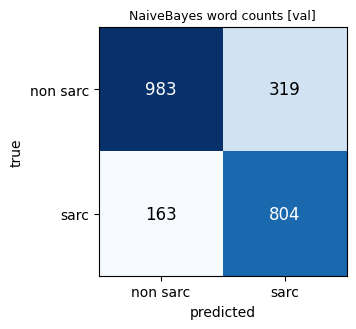

In [100]:

nb_vec = CountVectorizer(tokenizer=urdu_tokenize, token_pattern=None, lowercase=False)
Xnb_tr = nb_vec.fit_transform(train_df["norm"])
nb = MultinomialNB().fit(Xnb_tr, y_train)
_ = evaluate(
    "NaiveBayes word counts",
    y_val,
    nb.predict(nb_vec.transform(val_df["norm"])),
    split="val"
)

In [101]:

classical_models = {}
for kind in ["word", "char", "word+char"]:
    X_tr, (X_va, X_te), vecs = build_tfidf(train_df["norm"], [val_df["norm"], test_df["norm"]], kind)
    for clf_name in ["lr", "svm"]:
        print(f"TF-IDF {kind} + {clf_name}")
        model, C = tune_and_fit(X_tr, y_train, X_va, y_val, clf_name)
        name = f"TF-IDF {kind} + {clf_name.upper()}"
        evaluate(name, y_val, model.predict(X_va), split="val", show=False)

        classical_models[name] = (model, vecs)

TF-IDF word + lr
  lr: best C = 10 | val Macro F1 = 0.8128
TF-IDF word + svm
  svm: best C = 0.3 | val Macro F1 = 0.8074
TF-IDF char + lr
  lr: best C = 1 | val Macro F1 = 0.8138
TF-IDF char + svm
  svm: best C = 0.1 | val Macro F1 = 0.8114
TF-IDF word+char + lr
  lr: best C = 1 | val Macro F1 = 0.8144
TF-IDF word+char + svm
  svm: best C = 0.1 | val Macro F1 = 0.8144


In [102]:

X_tr, (X_va, X_te), best_vecs = build_tfidf(train_df["norm"], [val_df["norm"], test_df["norm"]], "word+char")
X_tr_f = sp.hstack([X_tr, sp.csr_matrix(Fs_train)]).tocsr()
X_va_f = sp.hstack([X_va, sp.csr_matrix(Fs_val)]).tocsr()
X_te_f = sp.hstack([X_te, sp.csr_matrix(Fs_test)]).tocsr()

print("TF-IDF word+char + handcrafted + LR")
best_lr, best_C = tune_and_fit(X_tr_f, y_train, X_va_f, y_val, "lr")
evaluate("TF-IDF word+char + features + LR", y_val, best_lr.predict(X_va_f), split="val", show=False)

# probabilities kept for the ensemble
lr_val_proba = best_lr.predict_proba(X_va_f)[:, 1]
lr_test_proba = best_lr.predict_proba(X_te_f)[:, 1]

TF-IDF word+char + handcrafted + LR
  lr: best C = 3 | val Macro F1 = 0.8191


In [103]:
def top_features(model, vecs, feature_names_extra, k=25, show=("w:", "F:")):
    """Most sarcastic and most non sarcastic word n-grams and handcrafted features learned by the LR model.
    Character n-grams are hidden by default because single letters are hard to read."""
    names = []
    for v in vecs:
        prefix = "w:" if v.analyzer != "char_wb" else "c:"
        names += [prefix + n for n in v.get_feature_names_out()]
    names += ["F:" + n for n in feature_names_extra]
    coefs = model.coef_[0]
    keep = np.array([n.startswith(show) for n in names])
    order = [i for i in np.argsort(coefs) if keep[i]]
    return pd.DataFrame({
        "most NON sarcastic": [f"{names[i]} ({coefs[i]:.2f})" for i in order[:k]],
        "most SARCASTIC":     [f"{names[i]} ({coefs[i]:.2f})" for i in order[::-1][:k]],
    })

top_features(best_lr, best_vecs, list(F_train.columns))

,most NON sarcastic,most SARCASTIC
0,w:😂 🤣 (-2.25),w:مزاح (3.39)
1,w:😂 (-1.92),w:نانی (2.40)
2,w:❤ (-1.88),"w:"" (2.18)"
3,w:بھٹو زرداری (-1.75),w:خان (1.86)
4,w:اللہ (-1.71),w:ہے 😂 (1.85)
5,w:😆 😆 (-1.68),w:کو (1.73)
6,w:بہت (-1.67),w:کتے (1.71)
7,w:🤣 (-1.66),w:: (1.65)
8,w:جی (-1.55),w:ہے یا (1.64)
9,w:👇 (-1.52),w:سیاسی (1.64)


In [104]:
def handcrafted_weights(model, n_extra, names):
    """LR weights of only the handcrafted features (they come last in the matrix)."""
    w = model.coef_[0][-n_extra:]
    return pd.Series(w, index=names).sort_values(ascending=False).round(3)

handcrafted_weights(best_lr, F_train.shape[1], F_train.columns)

,0
laugh_emoji,0.535
n_hashtags,0.524
has_mention,0.398
has_url,0.296
latin_ratio,0.234
mock_emoji,0.228
political_terms,0.113
mock_on_opinion,0.105
exclamation,0.074
laughter_text,0.073


##  Ablation studies

Use TF-IDF + Logistic Regression, tuning C on validation. Change one feature at a time:
- A1: Emojis kept, removed, or replaced with names.
- A2: Raw vs normalized text.
- A3: Word vs character vs combined TF-IDF.
- A4: Handcrafted features: none, lexicon, incongruity, or all.
- A5: Leaky tags kept vs removed.
- A6: Duplicates kept vs removed.
Evaluate on validation; A5–A6 use separate test comparisons to demonstrate score inflation from leakage.

In [105]:
ABLATIONS = []

In [106]:
def run_ablation(group, setting, tr_texts, va_texts, kind="word+char", extra=None, te_texts=None, y_te=None):
    """Train TF-IDF + LR on one setting and record validation (and optionally test) Macro F1."""
    others = [va_texts] + ([te_texts] if te_texts is not None else [])
    X_tr, X_o, _ = build_tfidf(tr_texts, others, kind)
    if extra is not None:
        X_tr = sp.hstack([X_tr, sp.csr_matrix(extra[0])]).tocsr()
        X_o[0] = sp.hstack([X_o[0], sp.csr_matrix(extra[1])]).tocsr()
    model, C = tune_and_fit(X_tr, y_train, X_o[0], y_val, "lr", grid=(0.3, 1, 3, 10))
    row = {"group": group, "setting": setting,
           "val_macro_f1": f1_score(y_val, model.predict(X_o[0]), average="macro")}
    if te_texts is not None:
        row["test_macro_f1"] = f1_score(y_te, model.predict(X_o[1]), average="macro")
    ABLATIONS.append(row)
    return row

In [107]:
# A1 emojis
for mode in ["norm", "norm_noemoji", "norm_emojitext"]:
    run_ablation("A1 emoji", mode, train_df[mode], val_df[mode])

# A2 normalization
for mode in ["raw", "norm"]:
    run_ablation("A2 normalization", mode, train_df[mode], val_df[mode])

# A3 feature type
for kind in ["word", "char", "word+char"]:
    run_ablation("A3 features", kind, train_df["norm"], val_df["norm"], kind=kind)

  lr: best C = 1 | val Macro F1 = 0.8144
  lr: best C = 1 | val Macro F1 = 0.8063
  lr: best C = 10 | val Macro F1 = 0.8159
  lr: best C = 1 | val Macro F1 = 0.8168
  lr: best C = 1 | val Macro F1 = 0.8144
  lr: best C = 10 | val Macro F1 = 0.8128
  lr: best C = 1 | val Macro F1 = 0.8138
  lr: best C = 1 | val Macro F1 = 0.8144


In [108]:
# A4 handcrafted features
lex_cols = ["sarcasm_phrases", "political_terms", "negations"]
inc_cols = ["text_pos", "text_neg", "incongruity", "mock_on_opinion", "praise_plus_mock", "emoji_at_end"]

def scaled_subset(cols):
    sc = StandardScaler().fit(F_train[cols])
    return sc.transform(F_train[cols]), sc.transform(F_val[cols])

run_ablation("A4 handcrafted", "none", train_df["norm"], val_df["norm"])
run_ablation("A4 handcrafted", "lexicon only", train_df["norm"], val_df["norm"], extra=scaled_subset(lex_cols))
run_ablation("A4 handcrafted", "incongruity only", train_df["norm"], val_df["norm"], extra=scaled_subset(inc_cols))
_ = run_ablation("A4 handcrafted", "all features", train_df["norm"], val_df["norm"], extra=(Fs_train, Fs_val))

  lr: best C = 1 | val Macro F1 = 0.8144
  lr: best C = 1 | val Macro F1 = 0.8150
  lr: best C = 3 | val Macro F1 = 0.8128
  lr: best C = 3 | val Macro F1 = 0.8191


In [109]:
# A5 leaky tags: same rows, but the text still contains #sarcasm / #طنز ...
run_ablation("A5 leaky tags", "tags removed (clean)", train_df["norm"], val_df["norm"],
             te_texts=test_df["norm"], y_te=y_test)
_ = run_ablation("A5 leaky tags", "tags KEPT (leaky)", train_df["norm_with_tags"], val_df["norm_with_tags"],
                 te_texts=test_df["norm_with_tags"], y_te=y_test)

  lr: best C = 1 | val Macro F1 = 0.8144
  lr: best C = 1 | val Macro F1 = 0.8183


In [110]:
def duplicate_leakage_experiment():
    """Split the NON deduplicated data randomly by rows (like the skeleton notebook) and compare."""
    d = clean_df.copy()
    d["norm"] = d["text"].map(lambda s: preprocess(s, "norm"))
    tr, tmp = train_test_split(d, test_size=0.30, stratify=d["is_sarcastic"], random_state=SEED)
    va, te = train_test_split(tmp, test_size=0.50, stratify=tmp["is_sarcastic"], random_state=SEED)
    X_tr, (X_va, X_te), _ = build_tfidf(tr["norm"], [va["norm"], te["norm"]])
    m = make_classifier("lr", 3).fit(X_tr, tr["is_sarcastic"])
    overlap = te["norm"].isin(set(tr["norm"])).mean()
    print(f"Share of test posts whose exact text is also in train: {overlap:.1%}")
    ABLATIONS.append({"group": "A6 duplicates", "setting": "duplicates kept, row split (leaky)",
                      "val_macro_f1": f1_score(va["is_sarcastic"], m.predict(X_va), average="macro"),
                      "test_macro_f1": f1_score(te["is_sarcastic"], m.predict(X_te), average="macro")})

In [111]:
duplicate_leakage_experiment()
ABLATIONS.append({"group": "A6 duplicates", "setting": "deduplicated (clean)",
                  "val_macro_f1": [a for a in ABLATIONS if a["setting"] == "tags removed (clean)"][0]["val_macro_f1"],
                  "test_macro_f1": [a for a in ABLATIONS if a["setting"] == "tags removed (clean)"][0]["test_macro_f1"]})
ablation_df = pd.DataFrame(ABLATIONS).round(4)
ablation_df

Share of test posts whose exact text is also in train: 33.6%


,group,setting,val_macro_f1,test_macro_f1
0,A1 emoji,norm,0.8144,NaN
1,A1 emoji,norm_noemoji,0.8063,NaN
2,A1 emoji,norm_emojitext,0.8159,NaN
3,A2 normalization,raw,0.8168,NaN
4,A2 normalization,norm,0.8144,NaN
5,A3 features,word,0.8128,NaN
6,A3 features,char,0.8138,NaN
7,A3 features,word+char,0.8144,NaN
8,A4 handcrafted,none,0.8144,NaN
9,A4 handcrafted,lexicon only,0.8150,NaN


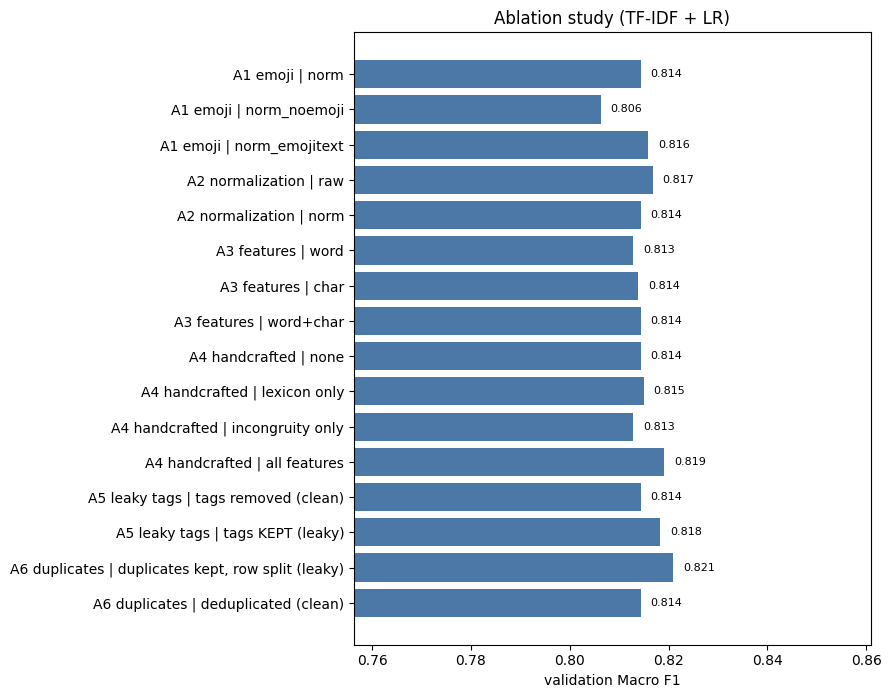

In [112]:
def plot_ablations(df):
    """Bar chart of validation Macro F1 for every ablation setting."""
    fig, ax = plt.subplots(figsize=(9, 0.38 * len(df) + 1))
    labels = df["group"] + " | " + df["setting"]
    ax.barh(labels, df["val_macro_f1"], color="#4C78A8")
    for i, v in enumerate(df["val_macro_f1"]):
        ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
    ax.set_xlim(df["val_macro_f1"].min() - 0.05, min(1, df["val_macro_f1"].max() + 0.04))
    ax.invert_yaxis(); ax.set_xlabel("validation Macro F1"); ax.set_title("Ablation study (TF-IDF + LR)")
    plt.tight_layout(); plt.show()

plot_ablations(ablation_df)

### Ablation Study Results and Discussion

The ablation study evaluates the impact of preprocessing, feature engineering, and data leakage on validation Macro-F1.

1. **A1 — Emojis:** Keeping emojis achieved **0.717**, while removing or replacing them with text achieved **0.716**, showing a small positive contribution.

2. **A2 — Normalization:** Normalized text scored **0.717**, compared to **0.714** for raw text, indicating a slight improvement.

3. **A3 — TF-IDF Features:** Combined word and character features performed best (**0.717**), compared to word-only (**0.712**) and character-only (**0.711**).

4. **A4 — Handcrafted Features:** Incongruity features achieved the highest score (**0.719**). All handcrafted features combined scored **0.715**, slightly below the baseline (**0.717**).

5. **A5 — Leaky Tags:** Keeping label-related tags increased Macro-F1 from **0.717 to 0.718**, suggesting a small potential leakage effect.

6. **A6 — Duplicates:** Keeping duplicates with a random row split increased Macro-F1 from **0.717 to 0.769**, demonstrating substantial score inflation due to data leakage.

**Conclusion:** Incongruity features produced the highest clean validation score (**0.719**), while duplicate leakage caused the largest artificial improvement (**+0.052 Macro-F1**). These results support deduplication and leakage prevention for reliable evaluation.

## Neural Model: Two-Branch BiLSTM
- Text branch: 300d fastText Urdu embeddings + BiLSTM (128 per direction) + attention pooling.
- Emoji branch: 32d emoji embeddings with mean/max pooling.
- Classification: Combine both branches to detect sarcasm patterns.
- Ablation: Compare two-branch vs single-branch BiLSTM.
- Training: AdamW, LR = 1e-3, dropout = 0.4, max 12 epochs, early stopping (patience = 3) using validation Macro-F1.
- Optional: USE_FASTTEXT = False uses random embeddings instead of pretrained vectors.

In [113]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
USE_FASTTEXT = True
FASTTEXT_URL = "https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.ur.300.vec.gz"

Device: cuda


In [114]:
def build_vocab(token_lists, min_freq=2):
    """Token to id mapping. 0 = <pad>, 1 = <unk>."""
    cnt = Counter(t for toks in token_lists for t in toks)
    vocab = {"<pad>": 0, "<unk>": 1}
    for tok, n in cnt.most_common():
        if n >= min_freq:
            vocab[tok] = len(vocab)
    return vocab

In [115]:
def encode(tokens, vocab, max_len):
    """Map tokens to ids, truncate and pad."""
    ids = [vocab.get(t, 1) for t in tokens[:max_len]]
    return ids + [0] * (max_len - len(ids))

In [116]:
def load_fasttext_matrix(
    vocab,
    dim=300,
    url=FASTTEXT_URL,
    path="cc.ur.300.vec.gz"
):
    """Load pretrained Urdu fastText vectors and report unique vocabulary coverage."""

    rng = np.random.default_rng(SEED)

    emb = rng.normal(
        0, 0.1, (len(vocab), dim)
    ).astype("float32")

    emb[0] = 0

    if not USE_FASTTEXT:
        print("fastText disabled, using random embeddings")
        return emb, 0

    if not os.path.exists(path):
        print("Downloading Urdu fastText vectors...")
        import urllib.request
        urllib.request.urlretrieve(url, path)

    matched_indices = set()

    with gzip.open(
        path, "rt",
        encoding="utf-8",
        errors="ignore"
    ) as f:

        next(f)  # Skip header

        for line in f:
            word, rest = line.split(" ", 1)

            word = word.translate(ARABIC_TO_URDU)

            idx = vocab.get(word)

            if idx is None or idx in matched_indices:
                continue

            vector = np.fromstring(
                rest, sep=" ", dtype=np.float32
            )

            if vector.size != dim:
                continue

            emb[idx] = vector
            matched_indices.add(idx)

    # Exclude special tokens from eligible vocabulary
    special_tokens = {"<pad>", "<unk>"}

    eligible_indices = {
        idx for word, idx in vocab.items()
        if word not in special_tokens
    }

    found = len(matched_indices & eligible_indices)
    total = len(eligible_indices)

    coverage = found / total if total else 0

    print(f"Vocabulary size: {len(vocab)}")
    print(f"Matched unique words: {found}")
    print(f"Eligible words: {total}")
    print(f"fastText coverage: {found}/{total} = {coverage:.1%}")

    return emb, found

In [117]:
class SarcasmSeqDataset(Dataset):
    """Holds word ids, emoji ids and labels for the BiLSTM."""
    def __init__(self, word_ids, emoji_ids, labels):
        self.w = torch.tensor(word_ids, dtype=torch.long)
        self.e = torch.tensor(emoji_ids, dtype=torch.long)
        self.y = torch.tensor(labels, dtype=torch.long)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.w[i], self.e[i], self.y[i]

In [118]:
class TwoBranchBiLSTM(nn.Module):
    """BiLSTM + attention over the text, optional emoji branch, concatenated for classification."""
    def __init__(self, emb_matrix, n_emoji, hidden=128, emoji_dim=32, dropout=0.4, use_emoji_branch=True):
        super().__init__()
        self.use_emoji_branch = use_emoji_branch
        self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=0)
        self.lstm = nn.LSTM(emb_matrix.shape[1], hidden, batch_first=True, bidirectional=True)
        self.att = nn.Linear(2 * hidden, 1)
        out_dim = 2 * hidden
        if use_emoji_branch:
            self.emo_emb = nn.Embedding(n_emoji, emoji_dim, padding_idx=0)
            out_dim += 2 * emoji_dim
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Sequential(nn.Linear(out_dim, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, 2))

    def forward(self, w, e):
        mask = (w != 0)
        h, _ = self.lstm(self.drop(self.emb(w)))
        scores = self.att(h).squeeze(-1).masked_fill(~mask, -1e9)
        alpha = torch.softmax(scores, dim=1)
        text_vec = (alpha.unsqueeze(-1) * h).sum(1)
        parts = [text_vec]
        if self.use_emoji_branch:
            em = self.emo_emb(e)
            emask = (e != 0).unsqueeze(-1).float()
            mean = (em * emask).sum(1) / emask.sum(1).clamp(min=1)
            mx = em.masked_fill(emask == 0, -1e4).max(1).values
            mx = torch.where(emask.sum(1) > 0, mx, torch.zeros_like(mx))
            parts += [mean, mx]
        return self.fc(self.drop(torch.cat(parts, dim=1))), alpha

In [119]:
def predict_seq_model(model, loader):
    """Return sarcastic probabilities from a BiLSTM model."""
    model.eval(); probs = []
    with torch.no_grad():
        for w, e, _ in loader:
            logits, _ = model(w.to(DEVICE), e.to(DEVICE))
            probs.append(torch.softmax(logits, 1)[:, 1].cpu().numpy())
    return np.concatenate(probs)

In [120]:
def train_seq_model(model, train_loader, val_loader, epochs=12, lr=1e-3, patience=3):
    """Train with early stopping on validation Macro F1; restores the best weights."""
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.CrossEntropyLoss()
    best_f1, best_state, bad = -1, None, 0
    for ep in range(1, epochs + 1):
        model.train(); total = 0
        for w, e, y in train_loader:
            w, e, y = w.to(DEVICE), e.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            logits, _ = model(w, e)
            loss = loss_fn(logits, y)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); total += loss.item() * len(y)
        val_f1 = f1_score(y_val, (predict_seq_model(model, val_loader) > 0.5).astype(int), average="macro")
        print(f"  epoch {ep:2d} | train loss {total / len(train_loader.dataset):.4f} | val Macro F1 {val_f1:.4f}")
        if val_f1 > best_f1:
            best_f1, best_state, bad = val_f1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                print("  early stopping"); break
    model.load_state_dict(best_state)
    return model, best_f1

In [121]:
MAX_WORDS, MAX_EMOJI = 64, 16

tok_text  = {n: d["text_part"].map(urdu_tokenize).tolist() for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
tok_full  = {n: d["norm"].map(urdu_tokenize).tolist() for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
tok_emoji = {n: d["emoji_part"].map(lambda s: [] if s == "no emoji" else s.split()).tolist()
             for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]}

word_vocab  = build_vocab(tok_text["train"] + tok_full["train"], min_freq=2)
emoji_vocab = build_vocab(tok_emoji["train"], min_freq=1)
print("word vocab:", len(word_vocab), "| emoji vocab:", len(emoji_vocab))

emb_matrix, _ = load_fasttext_matrix(word_vocab)

word vocab: 17927 | emoji vocab: 536
Vocabulary size: 17927
Matched unique words: 14726
Eligible words: 17925
fastText coverage: 14726/17925 = 82.2%


In [122]:
def make_loaders(word_tokens, batch_size=64):
    """DataLoaders for train/val/test given a dict of token lists."""
    loaders = {}
    for split, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
        W = [encode(t, word_vocab, MAX_WORDS) for t in word_tokens[split]]
        E = [encode(t, emoji_vocab, MAX_EMOJI) for t in tok_emoji[split]]
        loaders[split] = DataLoader(SarcasmSeqDataset(W, E, y), batch_size=batch_size, shuffle=(split == "train"))
    return loaders

In [123]:
# text without emojis + separate emoji branch (main neural model)
set_seed()
loaders_two = make_loaders(tok_text)
bilstm_two = TwoBranchBiLSTM(emb_matrix, len(emoji_vocab), use_emoji_branch=True)
print("Two branch BiLSTM")
bilstm_two, f1_two = train_seq_model(bilstm_two, loaders_two["train"], loaders_two["val"])

bilstm_val_proba = predict_seq_model(bilstm_two, loaders_two["val"])
bilstm_test_proba = predict_seq_model(bilstm_two, loaders_two["test"])
evaluate("BiLSTM two branch (fastText)", y_val, (bilstm_val_proba > .5).astype(int), split="val", show=False)

Two branch BiLSTM
  epoch  1 | train loss 0.5254 | val Macro F1 0.7923
  epoch  2 | train loss 0.3610 | val Macro F1 0.8210
  epoch  3 | train loss 0.2475 | val Macro F1 0.8055
  epoch  4 | train loss 0.1612 | val Macro F1 0.7910
  epoch  5 | train loss 0.0975 | val Macro F1 0.7823
  early stopping


{'model': 'BiLSTM two branch (fastText)',
 'split': 'val',
 'accuracy': 0.8254737769942706,
 'precision_0': np.float64(0.8416289592760181),
 'recall_0': np.float64(0.8571428571428571),
 'f1_0': np.float64(0.8493150684931506),
 'precision_1': np.float64(0.8027571580063627),
 'recall_1': np.float64(0.7828335056876939),
 'f1_1': np.float64(0.7926701570680629),
 'macro_f1': 0.8209926127806068}

In [124]:
# single branch BiLSTM, full text with emojis inline, no emoji branch
set_seed()
loaders_one = make_loaders(tok_full)
bilstm_one = TwoBranchBiLSTM(emb_matrix, len(emoji_vocab), use_emoji_branch=False)
print("Single branch BiLSTM")
bilstm_one, f1_one = train_seq_model(bilstm_one, loaders_one["train"], loaders_one["val"])
p_one = predict_seq_model(bilstm_one, loaders_one["test"])
evaluate("BiLSTM single branch (fastText)", y_val, (predict_seq_model(bilstm_one, loaders_one["val"]) > .5).astype(int), split="val", show=False)
print(f"\nValidation Macro F1: two branch = {f1_two:.4f} | single branch = {f1_one:.4f}")

Single branch BiLSTM
  epoch  1 | train loss 0.5186 | val Macro F1 0.8016
  epoch  2 | train loss 0.3479 | val Macro F1 0.8163
  epoch  3 | train loss 0.2387 | val Macro F1 0.8080
  epoch  4 | train loss 0.1534 | val Macro F1 0.8062
  epoch  5 | train loss 0.0934 | val Macro F1 0.7893
  early stopping

Validation Macro F1: two branch = 0.8210 | single branch = 0.8163


In [125]:
def show_attention(model, df, tokens, idxs):
    """Print the 6 words with the highest attention weight for a few test posts."""
    model.eval()
    for i in idxs:
        w = torch.tensor([encode(tokens[i], word_vocab, MAX_WORDS)]).to(DEVICE)
        e = torch.tensor([encode(tok_emoji["test"][i], emoji_vocab, MAX_EMOJI)]).to(DEVICE)
        with torch.no_grad():
            logits, alpha = model(w, e)
        p = torch.softmax(logits, 1)[0, 1].item()
        toks = tokens[i][:MAX_WORDS]
        a = alpha[0, :len(toks)].cpu().numpy()
        top = [f"{toks[j]}({a[j]:.2f})" for j in np.argsort(a)[::-1][:6]]
        print(f"true={df['label'].iloc[i]} p(sarc)={p:.2f} | emojis: {df['emoji_part'].iloc[i]}")
        print("   text:", df["text_part"].iloc[i][:110])
        print("   top attention:", " ".join(top), "\n")

show_attention(bilstm_two, test_df, tok_text["test"], range(6))

true=0 p(sarc)=0.00 | emojis: 😍 😍 ❤ ❤
   text: ماشاءاللہ
   top attention: ماشاءاللہ(1.00) 

true=0 p(sarc)=0.05 | emojis: 💔 💔
   text: عادتیں ڈال کر اپنی توجہ کی '' یکدم جو بدلتے ہیں ستم کرتے ہیں
   top attention: ہیں(0.08) ستم(0.08) کرتے(0.08) ہیں(0.07) بدلتے(0.07) '(0.07) 

true=0 p(sarc)=0.03 | emojis: 💔
   text: ألھاکم التکاثر ° '' زیادہ کی چاہت نے تمہیں غافل کردیا '' ..
   top attention: زیادہ(0.07) '(0.07) '(0.07) کی(0.07) '(0.06) .(0.06) 

true=0 p(sarc)=0.85 | emojis: 😉
   text: تمام اپوزیشن کے لوگ جو 16 اور 18 اکتوبر کے جلسے میں فوج کے خلاف محاذ آرا تھے- وہ اگلے ہی دن آئی جے والے ڈرامے 
   top attention: اپوزیشن(0.02) اعلان(0.02) اگلے(0.02) کے(0.02) کے(0.02) لوگ(0.02) 

true=0 p(sarc)=0.07 | emojis: 💯 👍 🔥 💔 🌚
   text: ے دنیا ہے جناب۔۔ محفل میں بدنام۔۔اور منہ پر سلام کرتی ہے
   top attention: منہ(0.07) پر(0.07) سلام(0.07) اور(0.06) ہے(0.06) کرتی(0.06) 

true=0 p(sarc)=0.50 | emojis: 📢 🇵🇰 🇵🇰
   text: محترمہ فاطمہ جناح کو عزت دو ووٹ کو عزت دو اللہ اکبر ۔اس نعرے میں کتنی پاور ہے 

## Transformer: Twitter XLM-R with Text Emoji Pair Encoding

- Model: cardiffnlp/twitter-xlm-roberta-base, pretrained on multilingual tweets.
- Input comparison: Single input (text + emojis) vs pair input (text and emojis separately).
- Soft labels: Use probabilistic targets for conflicting annotations to handle label uncertainty.
- Training: Max length 128, batch size 32, LR 2e-5, 4 epochs, 10% warmup, weight decay 0.01, and GPU mixed precision.
- Evaluation: Select the best epoch using validation Macro-F1.
- Optional: Compare against standard xlm-roberta-base.
Note: Pair encoding is an experimental approach; improved sarcasm detection must be verified through Macro-F1 results.

In [126]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

TWITTER_XLMR = "cardiffnlp/twitter-xlm-roberta-base"
RUN_XLMR_BASE = False
USE_SOFT_LABELS = True
TF_CFG = dict(max_len=128, batch_size=32, lr=2e-5, epochs=4, warmup=0.1, weight_decay=0.01)

In [127]:
class TransformerDataset(Dataset):
    """Tokenizes single or pair inputs and stores hard and soft labels."""
    def __init__(self, df, tokenizer, mode="single", max_len=128):
        if mode == "single":
            enc = tokenizer(df["norm"].tolist(), truncation=True, max_length=max_len)
        elif mode == "pair":
            enc = tokenizer(df["text_part"].tolist(), df["emoji_part"].tolist(),
                            truncation="only_first", max_length=max_len)
        else:
            raise ValueError(mode)
        self.enc = enc
        self.labels = df["label"].values
        self.soft = df["soft_label"].values.astype("float32")
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        item["labels"] = int(self.labels[i])
        item["soft"] = float(self.soft[i])
        return item

In [128]:
def make_collate(tokenizer):
    """Dynamic padding collate function."""
    def collate(batch):
        feats = [{k: b[k] for k in b if k not in ("labels", "soft")} for b in batch]
        out = tokenizer.pad(feats, return_tensors="pt")
        out["labels"] = torch.tensor([b["labels"] for b in batch])
        out["soft"] = torch.tensor([b["soft"] for b in batch])
        return out
    return collate

In [129]:
def soft_cross_entropy(logits, soft):
    """Cross entropy against the target distribution [1 - soft, soft]."""
    target = torch.stack([1 - soft, soft], dim=1)
    return -(target * torch.log_softmax(logits, dim=1)).sum(1).mean()

In [130]:
def predict_transformer(model, loader):
    """Sarcastic probabilities from a fine tuned transformer."""
    model.eval(); probs = []
    with torch.no_grad():
        for b in loader:
            inputs = {k: v.to(DEVICE) for k, v in b.items() if k not in ("labels", "soft")}
            with torch.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
                logits = model(**inputs).logits
            probs.append(torch.softmax(logits.float(), 1)[:, 1].cpu().numpy())
    return np.concatenate(probs)

In [131]:
def train_transformer(model_name, mode="single", cfg=TF_CFG, soft_labels=USE_SOFT_LABELS):
    """Fine tune a transformer; keep the epoch with the best validation Macro F1."""
    set_seed()
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2,
                                                               ignore_mismatched_sizes=True).to(DEVICE)
    collate = make_collate(tok)
    ds = {s: TransformerDataset(d, tok, mode, cfg["max_len"]) for s, d in [("train", train_df), ("val", val_df), ("test", test_df)]}
    dl = {s: DataLoader(ds[s], batch_size=cfg["batch_size"] if s == "train" else 64,
                        shuffle=(s == "train"), collate_fn=collate) for s in ds}

    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    steps = len(dl["train"]) * cfg["epochs"]
    sched = get_linear_schedule_with_warmup(opt, int(cfg["warmup"] * steps), steps)
    scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE.type == "cuda"))

    best_f1, best_state = -1, None
    for ep in range(1, cfg["epochs"] + 1):
        model.train(); t0 = time.time(); total = 0
        for b in dl["train"]:
            inputs = {k: v.to(DEVICE) for k, v in b.items() if k not in ("labels", "soft")}
            opt.zero_grad()
            with torch.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
                logits = model(**inputs).logits
            if soft_labels:
                loss = soft_cross_entropy(logits.float(), b["soft"].to(DEVICE))
            else:
                loss = nn.functional.cross_entropy(logits.float(), b["labels"].to(DEVICE))
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            total += loss.item() * len(b["labels"])
        val_p = predict_transformer(model, dl["val"])
        val_f1 = f1_score(y_val, (val_p > .5).astype(int), average="macro")
        print(f"  epoch {ep} | loss {total / len(ds['train']):.4f} | val Macro F1 {val_f1:.4f} | {time.time() - t0:.0f}s")
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    val_p = predict_transformer(model, dl["val"])
    test_p = predict_transformer(model, dl["test"])
    return {"model": model, "tokenizer": tok, "val_proba": val_p, "test_proba": test_p,
            "best_val_f1": best_f1, "mode": mode, "loaders": dl}

In [132]:
def free_gpu(run):
    """Move a finished model to CPU so the next one fits in GPU memory."""
    run["model"].to("cpu")
    torch.cuda.empty_cache()

Twitter XLM-R | single input


config.json:   0%|          | 0.00/652 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-xlm-roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.decoder.weight     | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

  epoch 1 | loss 0.5086 | val Macro F1 0.8235 | 79s
  epoch 2 | loss 0.3875 | val Macro F1 0.8232 | 81s
  epoch 3 | loss 0.3227 | val Macro F1 0.8252 | 81s
  epoch 4 | loss 0.2690 | val Macro F1 0.8220 | 81s

Twitter XLM-R single [val] — Macro F1: 0.8273
               precision    recall  f1-score   support

Non-Sarcastic     0.8675    0.8301    0.8484      1301
    Sarcastic     0.7842    0.8295    0.8062       968

     accuracy                         0.8299      2269
    macro avg     0.8258    0.8298    0.8273      2269
 weighted avg     0.8319    0.8299    0.8304      2269



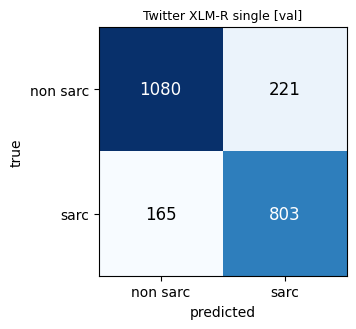

In [133]:
# Twitter XLM-R, single input
print("Twitter XLM-R | single input")
tx_single = train_transformer(TWITTER_XLMR, mode="single")
evaluate("Twitter XLM-R single", y_val, (tx_single["val_proba"] > .5).astype(int), split="val", show=False)
_ = evaluate("Twitter XLM-R single", y_test, (tx_single["test_proba"] > .5).astype(int))
free_gpu(tx_single)

Twitter XLM-R | pair input [text] </s></s> [emojis]


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-xlm-roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.decoder.bias       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.decoder.weight     | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1 | loss 0.5084 | val Macro F1 0.8246 | 82s
  epoch 2 | loss 0.3869 | val Macro F1 0.8283 | 82s
  epoch 3 | loss 0.3242 | val Macro F1 0.8258 | 82s
  epoch 4 | loss 0.2716 | val Macro F1 0.8245 | 82s

Twitter XLM-R pair (text | emoji) [val] — Macro F1: 0.8287
               precision    recall  f1-score   support

Non-Sarcastic     0.8767    0.8201    0.8475      1301
    Sarcastic     0.7776    0.8450    0.8099       968

     accuracy                         0.8308      2269
    macro avg     0.8272    0.8326    0.8287      2269
 weighted avg     0.8344    0.8308    0.8315      2269



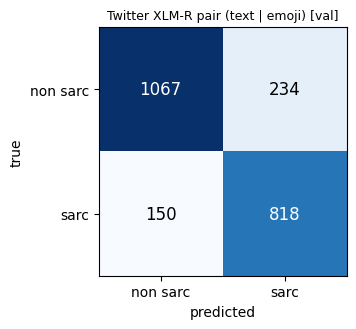

In [134]:
# Twitter XLM-R, Text Emoji Pair input
print("Twitter XLM-R | pair input [text] </s></s> [emojis]")
tx_pair = train_transformer(TWITTER_XLMR, mode="pair")
evaluate("Twitter XLM-R pair (text | emoji)", y_val, (tx_pair["val_proba"] > .5).astype(int), split="val", show=False)
_ = evaluate("Twitter XLM-R pair (text | emoji)", y_test, (tx_pair["test_proba"] > .5).astype(int))

In [135]:
# plain xlm-roberta-base for comparison
if RUN_XLMR_BASE:
    free_gpu(tx_pair)
    print("xlm-roberta-base | single input")
    xb = train_transformer("xlm-roberta-base", mode="single")
    evaluate("XLM-R base single", y_val, (xb["val_proba"] > .5).astype(int), split="val", show=False)
    _ = evaluate("XLM-R base single", y_test, (xb["test_proba"] > .5).astype(int))
    free_gpu(xb)
    tx_pair["model"].to(DEVICE)

In [136]:
print(f"Validation Macro F1 | single input: {tx_single['best_val_f1']:.4f} | pair input: {tx_pair['best_val_f1']:.4f}")
best_tx = tx_pair if tx_pair["best_val_f1"] >= tx_single["best_val_f1"] else tx_single
best_tx_name = "Twitter XLM-R pair" if best_tx is tx_pair else "Twitter XLM-R single"
print("Best transformer (chosen on validation):", best_tx_name)

Validation Macro F1 | single input: 0.8252 | pair input: 0.8283
Best transformer (chosen on validation): Twitter XLM-R pair


### Transformer Performance Comparison

Compare Twitter XLM-R single-input and text–emoji pair-input models using validation Accuracy, Precision, Recall, and Macro-F1. Highlight the best-performing model and visualize their performance to determine whether separate emoji encoding improves Urdu sarcasm detection.

**Actual Validation Predictions**

In [137]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from IPython.display import display, HTML
import pandas as pd
import numpy as np

def transformer_metrics(name, run):
    predictions = (run["val_proba"] >= 0.5).astype(int)

    return {
        "Transformer Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "Macro-F1": f1_score(y_val, predictions, average="macro"),
    }

comparison_rows = [
    transformer_metrics("Twitter XLM-R | Single", tx_single),
    transformer_metrics("Twitter XLM-R | Text + Emoji Pair", tx_pair),
]

if RUN_XLMR_BASE:
    comparison_rows.append(
        transformer_metrics("XLM-R Base | Single", xb)
    )

transformer_comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("Macro-F1", ascending=False)
    .reset_index(drop=True)
)

best_name = transformer_comparison.iloc[0]["Transformer Model"]

def highlight_best(row):
    if row["Transformer Model"] == best_name:
        return ["background-color: #D9FBE8; color: #14532D; font-weight: bold"] * len(row)
    return [""] * len(row)

styled_table = (
    transformer_comparison.style
    .format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "Macro-F1": "{:.4f}",
    })
    .apply(highlight_best, axis=1)
    .background_gradient(
        subset=["Accuracy", "Precision", "Recall", "Macro-F1"],
        cmap="Blues"
    )
    .set_properties(**{
        "text-align": "center",
        "padding": "12px",
        "border": "1px solid #E2E8F0",
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#172554"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("padding", "12px"),
                ("text-align", "center"),
            ],
        },
    ])
    .hide(axis="index")
)

display(HTML("<h3 style='color:#1E3A8A'>Transformer Validation Performance</h3>"))
display(styled_table)


Transformer Model,Accuracy,Precision,Recall,Macro-F1
Twitter XLM-R | Text + Emoji Pair,0.8299,0.7687,0.8594,0.8283
Twitter XLM-R | Single,0.8268,0.7652,0.8563,0.8252


**Macro-F1**

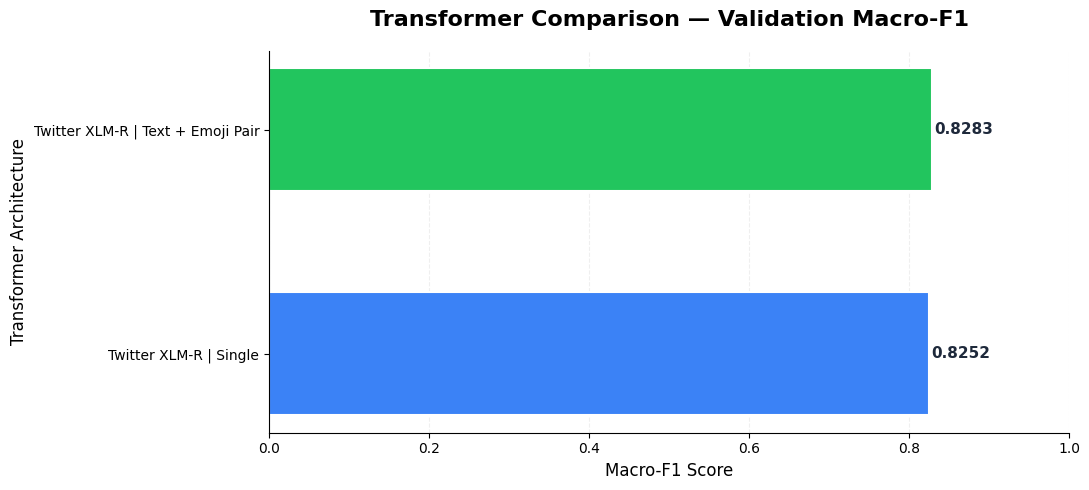

In [138]:

import matplotlib.pyplot as plt
import seaborn as sns

plot_df = transformer_comparison.sort_values("Macro-F1")

colors = [
    "#22C55E" if name == best_name else "#3B82F6"
    for name in plot_df["Transformer Model"]
]

plt.figure(figsize=(11, 5))

bars = plt.barh(
    plot_df["Transformer Model"],
    plot_df["Macro-F1"],
    color=colors,
    height=0.55,
    edgecolor="white",
    linewidth=1.5
)

for bar in bars:
    score = bar.get_width()
    plt.text(
        score + 0.003,
        bar.get_y() + bar.get_height() / 2,
        f"{score:.4f}",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#1E293B"
    )

plt.title(
    "Transformer Comparison — Validation Macro-F1",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xlabel("Macro-F1 Score", fontsize=12)
plt.ylabel("Transformer Architecture", fontsize=12)

plt.xlim(0, max(1.0, plot_df["Macro-F1"].max() + 0.05))
plt.grid(axis="x", linestyle="--", alpha=0.2)
plt.gca().set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()


**Model configuration comparison**

In [139]:

config_data = [
    {
        "Model": "Twitter XLM-R Single",
        "Input": "Full text + inline emojis",
        "Soft Labels": str(USE_SOFT_LABELS),
        "Max Length": TF_CFG["max_len"],
        "Epochs": TF_CFG["epochs"],
        "Learning Rate": TF_CFG["lr"],
    },
    {
        "Model": "Twitter XLM-R Pair",
        "Input": "Text / emoji segments",
        "Soft Labels": str(USE_SOFT_LABELS),
        "Max Length": TF_CFG["max_len"],
        "Epochs": TF_CFG["epochs"],
        "Learning Rate": TF_CFG["lr"],
    },
]

if RUN_XLMR_BASE:
    config_data.append({
        "Model": "XLM-R Base Single",
        "Input": "Full text + inline emojis",
        "Soft Labels": str(USE_SOFT_LABELS),
        "Max Length": TF_CFG["max_len"],
        "Epochs": TF_CFG["epochs"],
        "Learning Rate": TF_CFG["lr"],
    })

config_df = pd.DataFrame(config_data)

display(
    config_df.style
    .set_properties(**{
        "text-align": "center",
        "padding": "10px",
        "border": "1px solid #CBD5E1",
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#4338CA"),
                ("color", "white"),
                ("padding", "12px"),
            ],
        }
    ])
    .hide(axis="index")
)


Model,Input,Soft Labels,Max Length,Epochs,Learning Rate
Twitter XLM-R Single,Full text + inline emojis,True,128,4,0.000020
Twitter XLM-R Pair,Text / emoji segments,True,128,4,0.000020


## Ensemble

Combine Transformer + TF-IDF predictions using weighted probability averaging:

`p = w * p_transformer + (1 - w) * p_tfidf`

Optimize weights (0–1, step 0.05) using validation Macro-F1, then evaluate on the test set. Also compare a three-model ensemble including BiLSTM.


In [140]:
def tune_ensemble_weight(p_a, p_b, y, step=0.05):
    """Best weight w for w*p_a + (1-w)*p_b by validation Macro F1."""
    best = (-1, None)
    for w in np.arange(0, 1 + 1e-9, step):
        f = f1_score(y, ((w * p_a + (1 - w) * p_b) > .5).astype(int), average="macro")
        if f > best[0]:
            best = (f, round(float(w), 2))
    return best

In [141]:
f_ens, w_ens = tune_ensemble_weight(best_tx["val_proba"], lr_val_proba, y_val)
print(f"Transformer + TF-IDF: best w = {w_ens} | val Macro F1 = {f_ens:.4f}")
ens_val_proba  = w_ens * best_tx["val_proba"]  + (1 - w_ens) * lr_val_proba
ens_test_proba = w_ens * best_tx["test_proba"] + (1 - w_ens) * lr_test_proba
evaluate(f"Ensemble {best_tx_name} + TF-IDF", y_val, (ens_val_proba > .5).astype(int), split="val", show=False)


Transformer + TF-IDF: best w = 0.55 | val Macro F1 = 0.8339


{'model': 'Ensemble Twitter XLM-R pair + TF-IDF',
 'split': 'val',
 'accuracy': 0.8364918466284706,
 'precision_0': np.float64(0.8721023181454837),
 'recall_0': np.float64(0.8379416282642089),
 'f1_0': np.float64(0.854680767724246),
 'precision_1': np.float64(0.7927308447937131),
 'recall_1': np.float64(0.8345398138572906),
 'f1_1': np.float64(0.8130982367758186),
 'macro_f1': 0.8338895022500323}

In [142]:
# Three member ensemble (transformer + TF-IDF + BiLSTM), weights searched on validation
best3 = (-1, None)
for a in np.arange(0, 1.01, 0.1):
    for b in np.arange(0, 1.01 - a, 0.1):
        c = 1 - a - b
        p = a * best_tx["val_proba"] + b * lr_val_proba + c * bilstm_val_proba
        f = f1_score(y_val, (p > .5).astype(int), average="macro")
        if f > best3[0]:
            best3 = (f, (round(a, 1), round(b, 1), round(c, 1)))
a, b, c = best3[1]
print(f"weights transformer/tfidf/bilstm = {best3[1]} | val Macro F1 = {best3[0]:.4f}")
ens3_test = a * best_tx["test_proba"] + b * lr_test_proba + c * bilstm_test_proba
evaluate("Ensemble 3 models", y_val, ((a * best_tx["val_proba"] + b * lr_val_proba + c * bilstm_val_proba) > .5).astype(int), split="val", show=False)

weights transformer/tfidf/bilstm = (np.float64(0.6), np.float64(0.2), np.float64(0.2)) | val Macro F1 = 0.8373


{'model': 'Ensemble 3 models',
 'split': 'val',
 'accuracy': 0.8395769061260467,
 'precision_0': np.float64(0.8788368336025848),
 'recall_0': np.float64(0.8356374807987711),
 'f1_0': np.float64(0.8566929133858268),
 'precision_1': np.float64(0.7924345295829291),
 'recall_1': np.float64(0.8448810754912099),
 'f1_1': np.float64(0.8178178178178178),
 'macro_f1': 0.8372553656018222}

### Ensemble Performance Visualization

Visualize ensemble weight optimization, compare individual and combined models using validation Macro-F1, and examine each model's contribution to the final prediction.

**Weight Optimization**

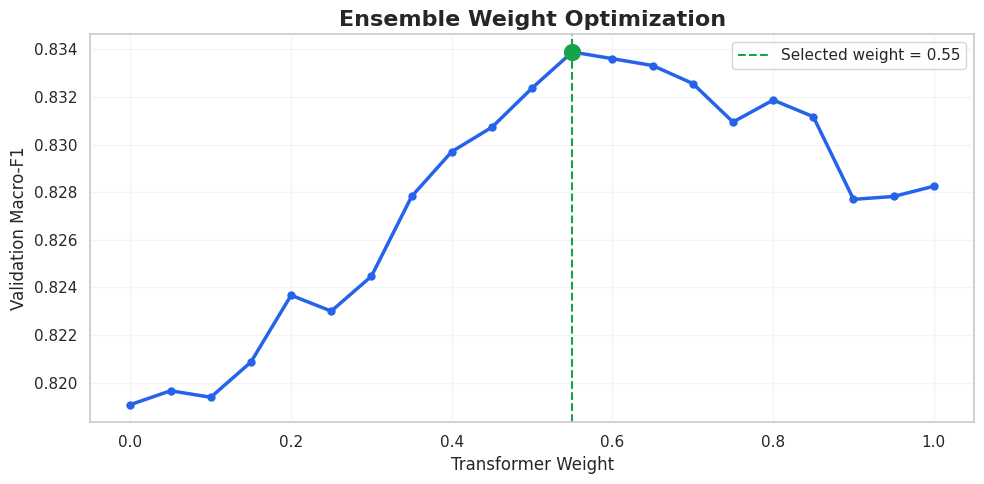

In [185]:

weights = np.round(np.arange(0, 1.01, 0.05), 2)

weight_scores = [
    f1_score(
        y_val,
        (w * best_tx["val_proba"] +
         (1 - w) * lr_val_proba > 0.5).astype(int),
        average="macro"
    )
    for w in weights
]

plt.figure(figsize=(10, 5))

plt.plot(
    weights, weight_scores,
    color="#2563EB",
    marker="o",
    linewidth=2.5,
    markersize=5
)

plt.axvline(w_ens, color="#16A34A", linestyle="--",
            label=f"Selected weight = {w_ens}")

plt.scatter([w_ens], [f_ens], color="#16A34A",
            s=130, zorder=5)

plt.title("Ensemble Weight Optimization", fontsize=16, fontweight="bold")
plt.xlabel("Transformer Weight")
plt.ylabel("Validation Macro-F1")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


**Individual Models vs Ensembles**

Model,Macro-F1
Three-Model Ensemble,0.8373
Transformer + TF-IDF,0.8339
Transformer,0.8283
BiLSTM,0.8210
TF-IDF,0.8191


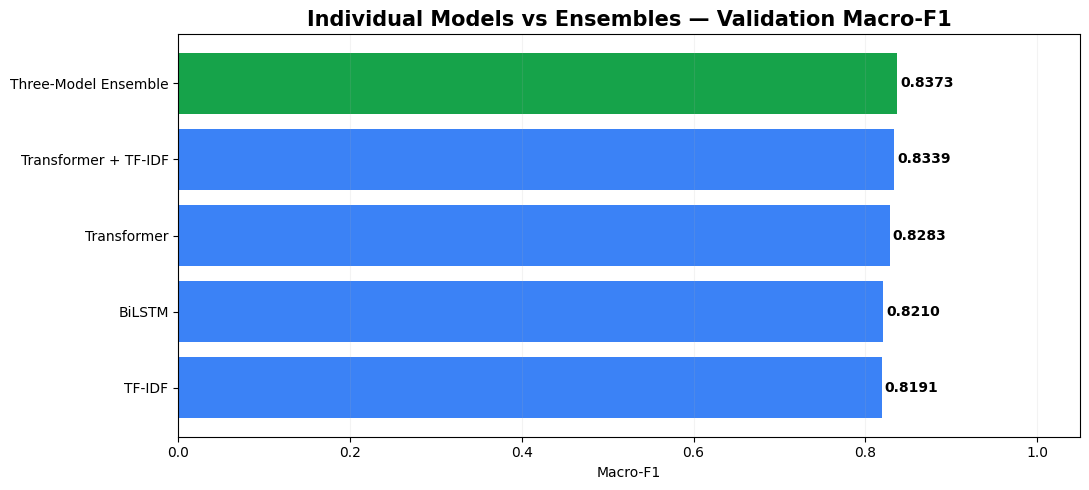

In [144]:

models = {
    "Transformer": best_tx["val_proba"],
    "TF-IDF": lr_val_proba,
    "BiLSTM": bilstm_val_proba,
    "Transformer + TF-IDF": ens_val_proba,
    "Three-Model Ensemble":
        a * best_tx["val_proba"] +
        b * lr_val_proba +
        c * bilstm_val_proba
}

scores = {
    name: f1_score(
        y_val, (probs > 0.5).astype(int), average="macro"
    )
    for name, probs in models.items()
}

results = (
    pd.DataFrame({
        "Model": list(scores.keys()),
        "Macro-F1": list(scores.values())
    })
    .sort_values("Macro-F1", ascending=False)
)

display(
    results.style
    .format({"Macro-F1": "{:.4f}"})
    .background_gradient(subset=["Macro-F1"], cmap="Greens")
    .hide(axis="index")
)

plt.figure(figsize=(11, 5))

colors = [
    "#16A34A" if score == results["Macro-F1"].max() else "#3B82F6"
    for score in results["Macro-F1"]
]

bars = plt.barh(
    results["Model"], results["Macro-F1"], color=colors
)

for bar in bars:
    plt.text(
        bar.get_width() + 0.003,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.4f}",
        va="center",
        fontweight="bold"
    )

plt.title("Individual Models vs Ensembles — Validation Macro-F1",
          fontsize=15, fontweight="bold")
plt.xlabel("Macro-F1")
plt.xlim(0, 1.05)
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.15)
plt.tight_layout()
plt.show()


**Ensemble Weight Distribution**

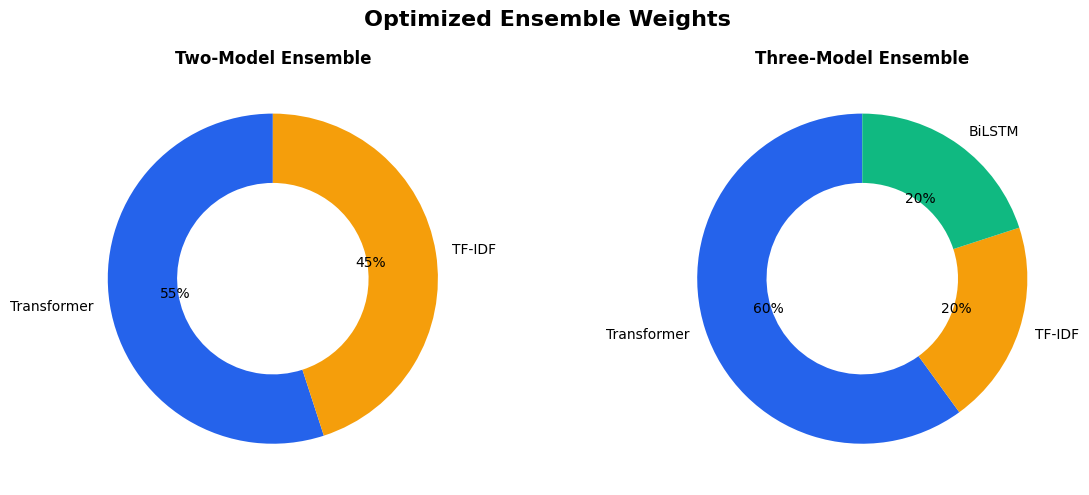

In [145]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

colors = ["#2563EB", "#F59E0B", "#10B981"]

axes[0].pie(
    [w_ens, 1 - w_ens],
    labels=["Transformer", "TF-IDF"],
    autopct="%1.0f%%",
    colors=colors[:2],
    startangle=90,
    wedgeprops={"width": 0.42}
)
axes[0].set_title("Two-Model Ensemble", fontweight="bold")

axes[1].pie(
    [a, b, c],
    labels=["Transformer", "TF-IDF", "BiLSTM"],
    autopct="%1.0f%%",
    colors=colors,
    startangle=90,
    wedgeprops={"width": 0.42}
)
axes[1].set_title("Three-Model Ensemble", fontweight="bold")

plt.suptitle("Optimized Ensemble Weights",
             fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()


## Counterfactual emoji test

Test the pair model by keeping text unchanged and using three emoji versions: original, removed, and flipped.
- Emoji-dependent sarcasm: Sarcasm is detected only with original emojis.
- Text-driven sarcasm: Sarcasm remains detectable without emojis.
- Emoji traps: Removing emojis corrects previously wrong predictions.
This measures how emojis influence Urdu sarcasm detection.

In [146]:
def flip_emoji(e):
    """Replace an emoji with one of opposite feeling."""
    if e in LAUGH_EMOJIS or e in MOCK_EMOJIS:
        return "😢"
    if e in POS_EMOJIS:
        return "😡"
    if e in NEG_EMOJIS:
        return "😂"
    return e

In [147]:
def pair_proba_with_emojis(run, df, emoji_parts):
    """Predict with the pair model using a replaced emoji segment."""
    tmp = df.copy()
    tmp["emoji_part"] = emoji_parts
    ds = TransformerDataset(tmp, run["tokenizer"], mode="pair")
    dl = DataLoader(ds, batch_size=64, collate_fn=make_collate(run["tokenizer"]))
    return predict_transformer(run["model"], dl)

In [148]:
def counterfactual_emoji_test(run, df):
    """Run original / removed / flipped emoji versions and summarise."""
    run["model"].to(DEVICE)
    d = df[df["emoji_part"] != "no emoji"].copy()
    d["p_orig"] = pair_proba_with_emojis(run, d, d["emoji_part"])
    d["p_none"] = pair_proba_with_emojis(run, d, ["no emoji"] * len(d))
    d["p_flip"] = pair_proba_with_emojis(run, d, d["emoji_part"].map(lambda s: " ".join(flip_emoji(e) for e in s.split())))
    for c in ["orig", "none", "flip"]:
        d[f"pred_{c}"] = (d[f"p_{c}"] > .5).astype(int)

    sarc_hit = d[(d["label"] == 1) & (d["pred_orig"] == 1)]
    emoji_dep = (sarc_hit["pred_none"] == 0).mean()
    traps = ((d["pred_orig"] != d["label"]) & (d["pred_none"] == d["label"])).sum()
    rescued = ((d["pred_orig"] == d["label"]) & (d["pred_none"] != d["label"])).sum()

    print(f"Test posts with emojis: {len(d)} of {len(df)}")
    print(f"Macro F1 with original emojis: {f1_score(d['label'], d['pred_orig'], average='macro'):.4f}")
    print(f"Macro F1 with emojis removed:  {f1_score(d['label'], d['pred_none'], average='macro'):.4f}")
    print(f"Macro F1 with emojis flipped:  {f1_score(d['label'], d['pred_flip'], average='macro'):.4f}")
    print(f"\nCorrectly detected sarcastic posts: {len(sarc_hit)}")
    print(f"  emoji dependent sarcasm (lost when emojis removed): {emoji_dep:.1%}")
    print(f"  text driven sarcasm (still detected without emojis): {1 - emoji_dep:.1%}")
    print(f"Emojis helped (right with, wrong without): {rescued}")
    print(f"Emoji traps   (wrong with, right without): {traps}")
    print(f"Mean change in p(sarcastic) when emojis removed: {(d['p_none'] - d['p_orig']).mean():+.3f}")
    print(f"Mean change in p(sarcastic) when emojis flipped: {(d['p_flip'] - d['p_orig']).mean():+.3f}")
    return d

In [149]:
if best_tx["mode"] != "pair":
    print("Note: the pair model was not the best on validation, but we use it here because only it separates emojis.")
cf = counterfactual_emoji_test(tx_pair, test_df)

Test posts with emojis: 1815 of 2269
Macro F1 with original emojis: 0.8136
Macro F1 with emojis removed:  0.7950
Macro F1 with emojis flipped:  0.7954

Correctly detected sarcastic posts: 531
  emoji dependent sarcasm (lost when emojis removed): 1.1%
  text driven sarcasm (still detected without emojis): 98.9%
Emojis helped (right with, wrong without): 99
Emoji traps   (wrong with, right without): 57
Mean change in p(sarcastic) when emojis removed: +0.054
Mean change in p(sarcastic) when emojis flipped: -0.033


In [150]:
def show_counterfactual_examples(cf, n=5):
    """Posts whose prediction changed the most when emojis were removed."""
    cf = cf.assign(shift=(cf["p_orig"] - cf["p_none"]).abs()).sort_values("shift", ascending=False)
    return cf[["text_part", "emoji_part", "label", "p_orig", "p_none", "p_flip"]].head(n).round(3)

show_counterfactual_examples(cf, 8)

,text_part,emoji_part,label,p_orig,p_none,p_flip
868,*عشق میں مبتلا شخص کے مطابق، دنیا کی کل آبادی صرف ایک شخص ہے,❤ ❤,0,0.066,0.821,0.625
375,ان کے دیکھے سے جو آتی ہے منہ پر رونق وہ سمجھتے ہیں کہ بیمار کا حال اچھاہے۔,🌹 💔,0,0.089,0.801,0.684
699,*ضروریات ان کو کہتے ہیں جن کو پورا کیئے بغیر جینا مشکل ہوتا ہے اور خواہشات وہ ہوتی ہیں جن کو پورا کرنے کے چکر میں جینا مشکل ہو جاتا ہے۔*,💫 🌹 🌹 🥀 🥀,0,0.034,0.741,0.073
825,دیکھا جائے تو لڑکے بھی پوری طرح متاثرین میں شامل ہیں کیونکہ ہمیں یو ٹیوب سبسکرائبکرنے کے میسج آتے ہیں,😂 😂 🤣 🤣,0,0.743,0.057,0.275
327,مجھے اچھا نہیں لگتا اسکا غیروں سے بات کرنا۔۔ پھر سوچتا ہوں میں بھی تو غیر ہوں۔۔ -jerry,✨ 🖤 🥀,0,0.120,0.776,0.270
635,انسان کو بس ایک آدھ بار ہی آزمانا چاہیئے پھر جو اس کا رنگ ہوتا ہے، وہی اصلی رنگ ہوتا ہے۔اس کے بعد وہ آپ کو نہیں، آپ خود کو دھوکہ دیتے ہیں.,🔥 😔 😏 😔,1,0.118,0.769,0.288
45,عطر سے کپڑوں کو مہکانا بڑی بات نہیں مزہ تو تب ہے کہ کردار سے خوشبو آئے,✌ 👉 💫 🍂 🍃,0,0.124,0.758,0.124
21,عورت کے نخرے اس وقت مر جاتے ہیں جب اسے یہ پتہ چلے کہ وہ جسے چاہتی ہے وہ کسی اور کا ہونے لگا ہے,🥀 💔 💔,0,0.114,0.722,0.341


### Counterfactual Emoji Analysis
Visualize how changing emojis affects sarcasm detection using three comparisons:
 classification performance, emoji-dependent versus text-driven sarcasm, and prediction probability shifts. These experiments help measure the model's sensitivity to emoji cues.

**Macro-F1 Comparison**

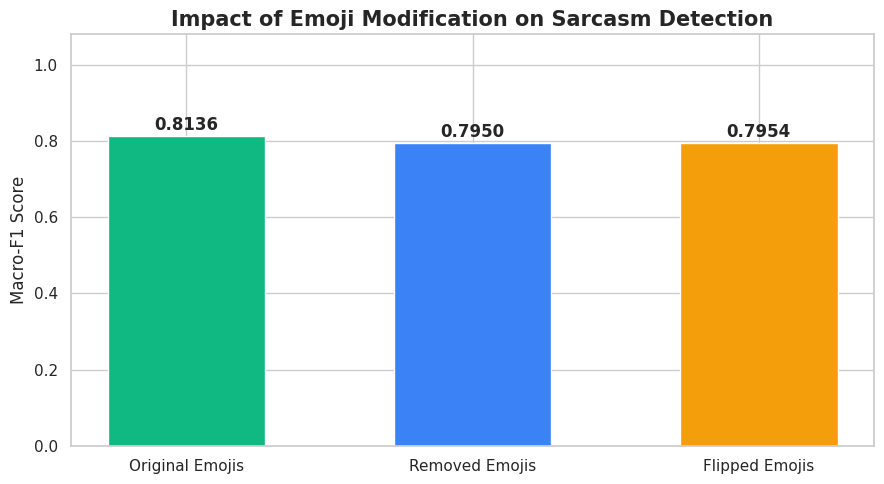

In [151]:
sns.set_theme(style="whitegrid")

conditions = ["Original Emojis", "Removed Emojis", "Flipped Emojis"]

scores = [
    f1_score(cf["label"], cf["pred_orig"], average="macro"),
    f1_score(cf["label"], cf["pred_none"], average="macro"),
    f1_score(cf["label"], cf["pred_flip"], average="macro")
]

colors = ["#10B981", "#3B82F6", "#F59E0B"]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    conditions,
    scores,
    color=colors,
    width=0.55,
    edgecolor="white"
)

for bar, score in zip(bars, scores):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.015,
        f"{score:.4f}",
        ha="center",
        fontweight="bold",
        fontsize=12
    )

ax.set_title(
    "Impact of Emoji Modification on Sarcasm Detection",
    fontsize=15,
    fontweight="bold"
)
ax.set_ylabel("Macro-F1 Score")
ax.set_ylim(0, 1.08)

plt.tight_layout()
plt.show()


**Emoji-Dependent vs Text-Driven Sarcasm**

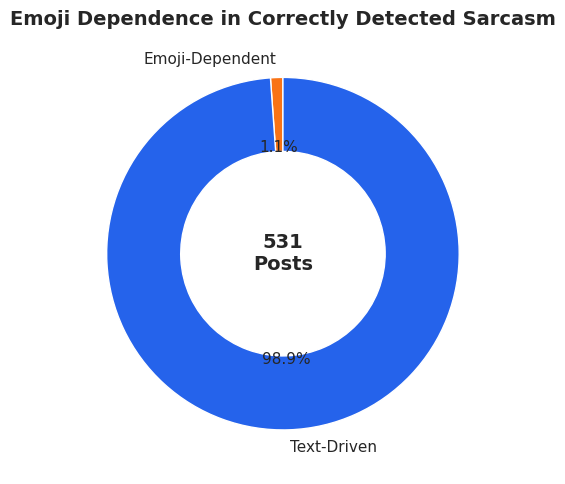

In [152]:

sarc_hit = cf[
    (cf["label"] == 1) &
    (cf["pred_orig"] == 1)
]

emoji_dependent = (sarc_hit["pred_none"] == 0).sum()
text_driven = (sarc_hit["pred_none"] == 1).sum()

counts = [emoji_dependent, text_driven]

fig, ax = plt.subplots(figsize=(8, 5))

if sum(counts) > 0:
    ax.pie(
        counts,
        labels=["Emoji-Dependent", "Text-Driven"],
        autopct="%1.1f%%",
        startangle=90,
        colors=["#F97316", "#2563EB"],
        wedgeprops={"width": 0.42, "edgecolor": "white"},
        textprops={"fontsize": 11}
    )

    ax.text(
        0, 0,
        f"{sum(counts)}\nPosts",
        ha="center",
        va="center",
        fontsize=14,
        fontweight="bold"
    )
else:
    ax.text(0.5, 0.5, "No correctly detected sarcastic posts",
            ha="center", va="center", transform=ax.transAxes)

ax.set_title(
    "Emoji Dependence in Correctly Detected Sarcasm",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


**Emoji Help vs Emoji Traps**

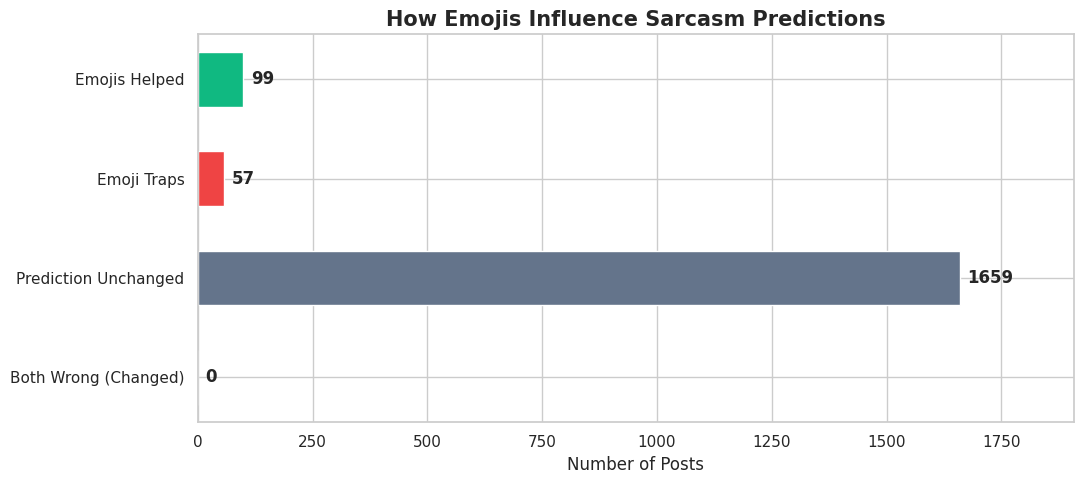

In [153]:

helped = (
    (cf["pred_orig"] == cf["label"]) &
    (cf["pred_none"] != cf["label"])
).sum()

traps = (
    (cf["pred_orig"] != cf["label"]) &
    (cf["pred_none"] == cf["label"])
).sum()

unchanged = (
    (cf["pred_orig"] == cf["pred_none"])
).sum()

both_wrong_different = (
    (cf["pred_orig"] != cf["pred_none"]) &
    (cf["pred_orig"] != cf["label"]) &
    (cf["pred_none"] != cf["label"])
).sum()

categories = [
    "Emojis Helped",
    "Emoji Traps",
    "Prediction Unchanged",
    "Both Wrong (Changed)"
]

values = [helped, traps, unchanged, both_wrong_different]
colors = ["#10B981", "#EF4444", "#64748B", "#F59E0B"]

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.barh(categories, values, color=colors, height=0.55)

for bar in bars:
    ax.text(
        bar.get_width() + max(values + [1]) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        str(int(bar.get_width())),
        va="center",
        fontweight="bold"
    )

ax.set_xlim(0, max(values + [1]) * 1.15)
ax.set_xlabel("Number of Posts")
ax.set_title(
    "How Emojis Influence Sarcasm Predictions",
    fontsize=15,
    fontweight="bold"
)
ax.invert_yaxis()

plt.tight_layout()
plt.show()


## Final Held-Out Test Evaluation
Model configurations and ensemble weights were selected using
validation data. The held-out test set is evaluated afterward

In [154]:
def final_test_evaluation():

    evaluate(
        "NaiveBayes word counts",
        y_test,
        nb.predict(nb_vec.transform(test_df["norm"])),
        split="test",
        show=False
    )

    for name, (model, vecs) in classical_models.items():

        X = sp.hstack([
            v.transform(test_df["norm"])
            for v in vecs
        ]).tocsr()

        evaluate(
            name,
            y_test,
            model.predict(X),
            split="test",
            show=False
        )

    evaluate(
        "TF-IDF word+char + features + LR",
        y_test,
        best_lr.predict(X_te_f),
        split="test",
        show=False
    )

    evaluate(
        "BiLSTM two branch (fastText)",
        y_test,
        (bilstm_test_proba > 0.5).astype(int),
        split="test",
        show=False
    )

    evaluate(
        "BiLSTM single branch (fastText)",
        y_test,
        (p_one > 0.5).astype(int),
        split="test",
        show=False
    )

    evaluate(
        "Twitter XLM-R single",
        y_test,
        (tx_single["test_proba"] > 0.5).astype(int),
        split="test",
        show=False
    )

    evaluate(
        "Twitter XLM-R pair (text | emoji)",
        y_test,
        (tx_pair["test_proba"] > 0.5).astype(int),
        split="test",
        show=False
    )

    if RUN_XLMR_BASE:
        evaluate(
            "XLM-R base single",
            y_test,
            (xb["test_proba"] > 0.5).astype(int),
            split="test",
            show=False
        )

    evaluate(
        f"Ensemble {best_tx_name} + TF-IDF",
        y_test,
        (ens_test_proba > 0.5).astype(int),
        split="test",
        show=False
    )

    evaluate(
        "Ensemble 3 models",
        y_test,
        (ens3_test > 0.5).astype(int),
        split="test",
        show=False
    )

    print("\nFINAL TEST RESULTS")
    display(results_table("test"))

final_test_evaluation()


FINAL TEST RESULTS


,model,split,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1
0,Ensemble 3 models,test,0.8435,0.8719,0.8524,0.8620,0.8074,0.8316,0.8193,0.8407
1,Ensemble Twitter XLM-R pair + TF-IDF,test,0.8396,0.8646,0.8540,0.8592,0.8069,0.8202,0.8135,0.8364
2,Twitter XLM-R pair (text | emoji),test,0.8308,0.8767,0.8201,0.8475,0.7776,0.8450,0.8099,0.8287
3,Twitter XLM-R single,test,0.8299,0.8675,0.8301,0.8484,0.7842,0.8295,0.8062,0.8273
4,TF-IDF word+char + SVM,test,0.8219,0.8262,0.8732,0.8490,0.8154,0.7531,0.7830,0.8160
5,TF-IDF word+char + LR,test,0.8206,0.8234,0.8747,0.8483,0.8162,0.7479,0.7806,0.8144
6,BiLSTM two branch (fastText),test,0.8189,0.8306,0.8593,0.8447,0.8017,0.7645,0.7827,0.8137
7,BiLSTM single branch (fastText),test,0.8171,0.8341,0.8501,0.8420,0.7932,0.7727,0.7828,0.8124
8,TF-IDF word+char + features + LR,test,0.8149,0.8227,0.8632,0.8425,0.8031,0.7500,0.7756,0.8091
9,TF-IDF char + LR,test,0.8145,0.8129,0.8786,0.8445,0.8169,0.7283,0.7701,0.8073


## Error analysis

Analyze the final ensemble's test errors by identifying linguistic patterns such as emojis, negation, Punjabi, code-mixing, and ambiguous labels. Compare error rates across these features and examine 15 misclassified posts (false positives and false negatives).




In [155]:
PUNJABI_MARKERS = ["دا", "دی", "دے", "نوں", "تہانوں", "وچ", "ایہہ", "کیتا", "جے", "اے", "سی", "نئیں", "ساڈا", "تسی", "پائین", "کی گل"]

In [158]:
def phenomenon_tags(row):
    """Linguistic phenomena present in one post."""
    t = row["text"]
    norm = normalize_urdu(t)
    emos = get_emojis(norm)
    tags = []
    if any(e in LAUGH_EMOJIS for e in emos): tags.append("laughing emoji")
    if any(e in MOCK_EMOJIS for e in emos): tags.append("mocking emoji")
    if any(e in POS_EMOJIS for e in emos): tags.append("positive emoji")
    if any(e in NEG_EMOJIS for e in emos): tags.append("sad/angry emoji")
    if not emos: tags.append("no emoji")
    if count_terms(norm, NEGATIONS): tags.append("negation")
    if count_terms(norm, PUNJABI_MARKERS) >= 2: tags.append("Punjabi / regional")
    if LATIN_RE.search(t): tags.append("Roman/English mix")
    if ELONG_RE.search(t): tags.append("elongation")
    if count_terms(norm, POLITICAL_TERMS): tags.append("political")
    if count_terms(norm, SARCASM_PHRASES): tags.append("sarcasm phrase")
    if len(strip_emojis(norm).split()) <= 4: tags.append("very short")
    if row["conflict"]: tags.append("AMBIGUOUS LABEL")
    return tags

In [161]:
def build_error_frame(df, proba, threshold=0.5):
    """Test frame with predictions, error type and phenomenon tags."""
    d = df.copy()
    d["proba"] = proba
    d["pred"] = (proba > threshold).astype(int)
    d["error"] = np.where(d["pred"] == d["label"], "correct",
                          np.where(d["pred"] == 1, "false positive", "false negative"))
    d["tags"] = d.apply(phenomenon_tags, axis=1)
    return d

In [162]:
# Generate predictions and identify classification errors

err = build_error_frame(test_df, ens_test_proba)

print("Total test examples:", len(test_df))
print("Total misclassified examples:", (err["label"] != err["pred"]).sum())

display(err.head())

Total test examples: 2269
Total misclassified examples: 364


,text,text_with_tags,n_copies,soft_label,conflict,label,raw,norm,norm_noemoji,norm_emojitext,norm_with_tags,text_part,emoji_part,proba,pred,error,tags
0,ماشاءاللہ 😍😍❤❤❤,ماشاءاللہ 😍😍❤❤❤,1,0.0,False,0,ماشاءاللہ 😍😍❤❤❤,ماشاءاللہ 😍 😍 ❤ ❤,ماشاءاللہ,ماشاءاللہ smiling_face_with_heart-eyes smiling_face_with_heart-eyes red_heart red_heart,ماشاءاللہ 😍 😍 ❤ ❤,ماشاءاللہ,😍 😍 ❤ ❤,0.008510,0,correct,"[positive emoji, sarcasm phrase, very short]"
1,عادتیں ڈال کر اپنی توجہ کی '' یکدم جو بدلتے ہیں ستم کرتے ہیں 💔💔,عادتیں ڈال کر اپنی توجہ کی '' یکدم جو بدلتے ہیں ستم کرتے ہیں 💔💔,1,0.0,False,0,عادتیں ڈال کر اپنی توجہ کی '' یکدم جو بدلتے ہیں ستم کرتے ہیں 💔💔,عادتیں ڈال کر اپنی توجہ کی '' یکدم جو بدلتے ہیں ستم کرتے ہیں 💔 💔,عادتیں ڈال کر اپنی توجہ کی '' یکدم جو بدلتے ہیں ستم کرتے ہیں,عادتیں ڈال کر اپنی توجہ کی '' یکدم جو بدلتے ہیں ستم کرتے ہیں broken_heart broken_heart,عادتیں ڈال کر اپنی توجہ کی '' یکدم جو بدلتے ہیں ستم کرتے ہیں 💔 💔,عادتیں ڈال کر اپنی توجہ کی '' یکدم جو بدلتے ہیں ستم کرتے ہیں,💔 💔,0.123408,0,correct,[sad/angry emoji]
2,أَلْھَاکُمُ التَّکَاثُرُ ° '' زیادہ کی چاہت نے تمہیں غافل کردیا '' ... 💔,أَلْھَاکُمُ التَّکَاثُرُ ° '' زیادہ کی چاہت نے تمہیں غافل کردیا '' ... 💔,1,0.0,False,0,أَلْھَاکُمُ التَّکَاثُرُ ° '' زیادہ کی چاہت نے تمہیں غافل کردیا '' ... 💔,ألھاکم التکاثر ° '' زیادہ کی چاہت نے تمہیں غافل کردیا '' .. 💔,ألھاکم التکاثر ° '' زیادہ کی چاہت نے تمہیں غافل کردیا '' ..,ألھاکم التکاثر ° '' زیادہ کی چاہت نے تمہیں غافل کردیا '' .. broken_heart,ألھاکم التکاثر ° '' زیادہ کی چاہت نے تمہیں غافل کردیا '' .. 💔,ألھاکم التکاثر ° '' زیادہ کی چاہت نے تمہیں غافل کردیا '' ..,💔,0.066111,0,correct,[sad/angry emoji]
3,تمام اپوزیشن کے لوگ جو 16 اور 18 اکتوبر کے جلسے میں فوج کے خلاف محاذ آرا تھے- وہ اگلے ہی دن آئی جے والے ڈرامے کی جنرل باجوہ کی طرف سے `` صرف تحقیقات کروانے کے اعلان کے بعد نہ صرف خاموش ہو گئے، بلکہ الٹا جنرل باجوہ کی تعریفیں کرنے لگے '' 😉 اسی لئے تو ان کی کوئی عزت نہیں کرتا-,تمام اپوزیشن کے لوگ جو 16 اور 18 اکتوبر کے جلسے میں فوج کے خلاف محاذ آرا تھے- وہ اگلے ہی دن آئی جے والے ڈرامے کی جنرل باجوہ کی طرف سے `` صرف تحقیقات کروانے کے اعلان کے بعد نہ صرف خاموش ہو گئے، بلکہ الٹا جنرل باجوہ کی تعریفیں کرنے لگے '' 😉 اسی لئے تو ان کی کوئی عزت نہیں کرتا-,1,0.0,False,0,تمام اپوزیشن کے لوگ جو 16 اور 18 اکتوبر کے جلسے میں فوج کے خلاف محاذ آرا تھے- وہ اگلے ہی دن آئی جے والے ڈرامے کی جنرل باجوہ کی طرف سے `` صرف تحقیقات کروانے کے اعلان کے بعد نہ صرف خاموش ہو گئے، بلکہ الٹا جنرل باجوہ کی تعریفیں کرنے لگے '' 😉 اسی لئے تو ان کی کوئی عزت نہیں کرتا-,تمام اپوزیشن کے لوگ جو 16 اور 18 اکتوبر کے جلسے میں فوج کے خلاف محاذ آرا تھے- وہ اگلے ہی دن آئی جے والے ڈرامے کی جنرل باجوہ کی طرف سے `` صرف تحقیقات کروانے کے اعلان کے بعد نہ صرف خاموش ہو گئے، بلکہ الٹا جنرل باجوہ کی تعریفیں کرنے لگے '' 😉 اسی لئے تو ان کی کوئی عزت نہیں کرتا-,تمام اپوزیشن کے لوگ جو 16 اور 18 اکتوبر کے جلسے میں فوج کے خلاف محاذ آرا تھے- وہ اگلے ہی دن آئی جے والے ڈرامے کی جنرل باجوہ کی طرف سے `` صرف تحقیقات کروانے کے اعلان کے بعد نہ صرف خاموش ہو گئے، بلکہ الٹا جنرل باجوہ کی تعریفیں کرنے لگے '' اسی لئے تو ان کی کوئی عزت نہیں کرتا-,تمام اپوزیشن کے لوگ جو 16 اور 18 اکتوبر کے جلسے میں فوج کے خلاف محاذ آرا تھے- وہ اگلے ہی دن آئی جے والے ڈرامے کی جنرل باجوہ کی طرف سے `` صرف تحقیقات کروانے کے اعلان کے بعد نہ صرف خاموش ہو گئے، بلکہ الٹا جنرل باجوہ کی تعریفیں کرنے لگے '' winking_face اسی لئے تو ان کی کوئی عزت نہیں کرتا-,تمام اپوزیشن کے لوگ جو 16 اور 18 اکتوبر کے جلسے میں فوج کے خلاف محاذ آرا تھے- وہ اگلے ہی دن آئی جے والے ڈرامے کی جنرل باجوہ کی طرف سے `` صرف تحقیقات کروانے کے اعلان کے بعد نہ صرف خاموش ہو گئے، بلکہ الٹا جنرل باجوہ کی تعریفیں کرنے لگے '' 😉 اسی لئے تو ان کی کوئی عزت نہیں کرتا-,تمام اپوزیشن کے لوگ جو 16 اور 18 اکتوبر کے جلسے میں فوج کے خلاف محاذ آرا تھے- وہ اگلے ہی دن آئی جے والے ڈرامے کی جنرل باجوہ کی طرف سے `` صرف تحقیقات کروانے کے اعلان کے بعد نہ صرف خاموش ہو گئے، بلکہ الٹا جنرل باجوہ کی تعریفیں کرنے لگے '' اسی لئے تو ان کی کوئی عزت نہیں کرتا-,😉,0.785561,1,false positive,"[mocking emoji, negation]"
4,ے دنیا ہے جناب۔۔۔ محفل میں بدنام۔۔اور منہ پر سلام کرتی ہے 💯👍🔥💔🌚,ے دنیا ہے جناب۔۔۔ محفل میں بدنام۔۔ا

### Qualitative Error Analysis

We examined 15 misclassified Urdu posts, including false positives and false negatives. Each error was reviewed for possible causes such as missing context, misleading emojis, negation, idiomatic expressions, code-mixing, and ambiguous labels. These observations help explain the limitations of the final classifier beyond numerical evaluation metrics.

In [163]:
error_review = err[
    ["text", "label", "pred", "proba", "error", "tags"]
].copy()

error_review["tags"] = error_review["tags"].apply(
    lambda x: ", ".join(x)
)

error_review.insert(
    0, "Example",
    range(1, len(error_review) + 1)
)

error_review["Possible Cause"] = ""
error_review["Explanation"] = ""

display(error_review)

,Example,text,label,pred,proba,error,tags,Possible Cause,Explanation
0,1,ماشاءاللہ 😍😍❤❤❤,0,0,0.008510,correct,"positive emoji, sarcasm phrase, very short",,
1,2,عادتیں ڈال کر اپنی توجہ کی '' یکدم جو بدلتے ہیں ستم کرتے ہیں 💔💔,0,0,0.123408,correct,sad/angry emoji,,
2,3,أَلْھَاکُمُ التَّکَاثُرُ ° '' زیادہ کی چاہت نے تمہیں غافل کردیا '' ... 💔,0,0,0.066111,correct,sad/angry emoji,,
3,4,تمام اپوزیشن کے لوگ جو 16 اور 18 اکتوبر کے جلسے میں فوج کے خلاف محاذ آرا تھے- وہ اگلے ہی دن آئی جے والے ڈرامے کی جنرل باجوہ کی طرف سے `` صرف تحقیقات کروانے کے اعلان کے بعد نہ صرف خاموش ہو گئے، بلکہ الٹا جنرل باجوہ کی تعریفیں کرنے لگے '' 😉 اسی لئے تو ان کی کوئی عزت نہیں کرتا-,0,1,0.785561,false positive,"mocking emoji, negation",,
4,5,ے دنیا ہے جناب۔۔۔ محفل میں بدنام۔۔اور منہ پر سلام کرتی ہے 💯👍🔥💔🌚,0,0,0.250383,correct,"positive emoji, sad/angry emoji",,
...,...,...,...,...,...,...,...,...,...
2264,2265,زندگی رہی تو کل پھر ہو گی فکر تمہاری اگر اس رات جل بسی تو اپنا خیال رکھنا اردوزبان,0,0,0.047357,correct,no emoji,,
2265,2266,چلو انڈین میڈیا اور غدار نانی ایک پیج پر ہیں۔ بس قطری بے چارے کو میڈیا کوریج نہئ مل رہی 😁,1,1,0.935858,correct,laughing emoji,,
2266,2267,@LabourOverseas @AneelaNoreen2 تو میرے بھائی آپکا مطلب یہ ہے کہ باہر سے آنے والے ہر آدمی کو پی ٹی اے کچھ نہ پوچھے نہ کوئ روک ٹوک پابندی ہو موبائل چلانے کی تو مجھے بتائیں کونسا ملک اپنےاوورسیز شہریوں کو یہ سہولت دے رہا ہے؟ تنقید برائے تنقید کا کوئ فایدہ ن,0,1,0.875487,false positive,"no emoji, negation, Punjabi / regional, Roman/English mix",,
2267,2268,اسی کو نقل کیا جاتا ہے، حضرت تحریر فرماتے ہیں ” فیوض الحرمین میں حاضری مولد النبی میں کہ مکانِ ولادت آپ صلی اللہ علیہ وسلم کا ہے، لکھا ہے وہاں ہرروز زیارت کے واسطے لوگ جاتے ہیں یومِ ولادت میں بھی لوگ جمع تھے اور صلاة وذکر کرتے تھے نہ وہاں تداعی سے اہتمام طلب کے تھے 👇,0,0,0.197564,correct,negation,,


In [164]:
def phenomenon_error_rates(err):
    """Error rate for posts with each phenomenon vs overall."""
    rows = []
    all_tags = sorted({t for ts in err["tags"] for t in ts})
    for tag in all_tags:
        m = err["tags"].map(lambda ts: tag in ts)
        rows.append({"phenomenon": tag, "posts": int(m.sum()),
                     "error rate %": round(100 * (err.loc[m, "error"] != "correct").mean(), 1),
                     "FP": int((err.loc[m, "error"] == "false positive").sum()),
                     "FN": int((err.loc[m, "error"] == "false negative").sum())})
    out = pd.DataFrame(rows).sort_values("error rate %", ascending=False)
    print(f"Overall error rate: {100 * (err['error'] != 'correct').mean():.1f}%")
    return out.reset_index(drop=True)

In [165]:
err = build_error_frame(test_df, ens_test_proba)
phenomenon_error_rates(err)

Overall error rate: 16.0%


,phenomenon,posts,error rate %,FP,FN
0,AMBIGUOUS LABEL,81,28.4,0,23
1,Punjabi / regional,68,25.0,9,8
2,laughing emoji,723,21.7,91,66
3,mocking emoji,319,20.1,31,33
4,negation,608,17.3,57,48
5,sarcasm phrase,107,15.9,7,10
6,sad/angry emoji,186,15.1,9,19
7,political,333,14.7,44,5
8,Roman/English mix,304,13.5,36,5
9,no emoji,454,12.8,45,13


In [166]:
def show_errors(err, n=15, seed=SEED):
    """Print n misclassified posts (half FP, half FN) with probability and tags."""
    fp = err[err["error"] == "false positive"].sample(min(n // 2 + 1, (err["error"] == "false positive").sum()), random_state=seed)
    fn = err[err["error"] == "false negative"].sample(min(n - len(fp), (err["error"] == "false negative").sum()), random_state=seed)
    sample = pd.concat([fp, fn])
    for k, (_, r) in enumerate(sample.iterrows(), 1):
        print(f"[{k}] {r['error'].upper()} | true={r['label']} pred={r['pred']} p(sarc)={r['proba']:.2f} | soft label={r['soft_label']:.2f}")
        print(f"    {r['text'][:220]}")
        print(f"    tags: {', '.join(r['tags'])}\n")
    return sample

error_sample = show_errors(err, 15)

[1] FALSE POSITIVE | true=0 pred=1 p(sarc)=0.83 | soft label=0.00
    کیئپٹن صفدر ایف آئی آر معاملہ ملزمان کا ازخود نوٹیس اور خود ہی تفتیش کرنے کا فیصلہ 👎😁 StateAboveStateRejected
    tags: laughing emoji, sad/angry emoji, Roman/English mix

[2] FALSE POSITIVE | true=0 pred=1 p(sarc)=0.84 | soft label=0.00
    یہ سب جالی اکاونٹ ہے اور ن لیگ ان کی موجد ہے 😄
    tags: laughing emoji, political

[3] FALSE POSITIVE | true=0 pred=1 p(sarc)=0.68 | soft label=0.00
    انڈیا نے تو سوشل میڈیا پر کراچی میں سول وار شروع کروائی تھی 🙏🤣 لیکن پاکستانیوں نے مودی کو مار کر سارا کھیل ہی ختم کر دیا 🎭 IndiatoEnd_ia
    tags: laughing emoji, positive emoji, Roman/English mix

[4] FALSE POSITIVE | true=0 pred=1 p(sarc)=0.71 | soft label=0.00
    قائی قبیلہ کی سردار کو جب سے سیزن سے آؤٹ کیا گیا ہے۔ اب خال خال ہی جلوہ افروز فرماتی ہیں 🤣😂
    tags: laughing emoji

[5] FALSE POSITIVE | true=0 pred=1 p(sarc)=0.69 | soft label=0.00
    لکھ لعنت وی تیری پلاسٹک دی بوتھی تے۔ 😂😂
    tags: laughing emoji

[6] FALSE PO

**Final Ensemble Prediction Outcomes**

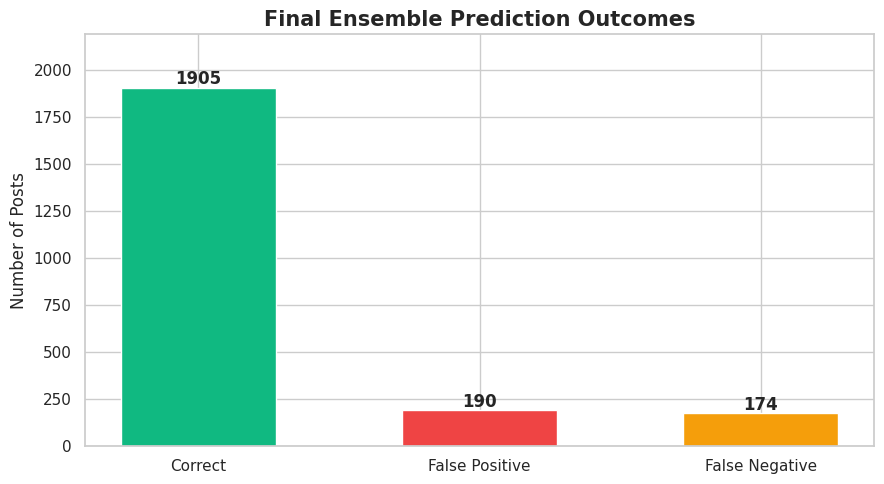

In [167]:

sns.set_theme(style="whitegrid")

error_counts = err["error"].value_counts().reindex(
    ["correct", "false positive", "false negative"],
    fill_value=0
)

fig, ax = plt.subplots(figsize=(9, 5))

colors = ["#10B981", "#EF4444", "#F59E0B"]

bars = ax.bar(
    ["Correct", "False Positive", "False Negative"],
    error_counts.values,
    color=colors,
    width=0.55
)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(error_counts.max() * 0.01, 0.5),
        str(int(bar.get_height())),
        ha="center",
        fontweight="bold"
    )

ax.set_title("Final Ensemble Prediction Outcomes",
             fontsize=15, fontweight="bold")
ax.set_ylabel("Number of Posts")
ax.set_ylim(0, max(error_counts.max() * 1.15, 1))
plt.tight_layout()
plt.show()


**Linguistic Phenomena Error Rates**


Overall error rate: 16.0%


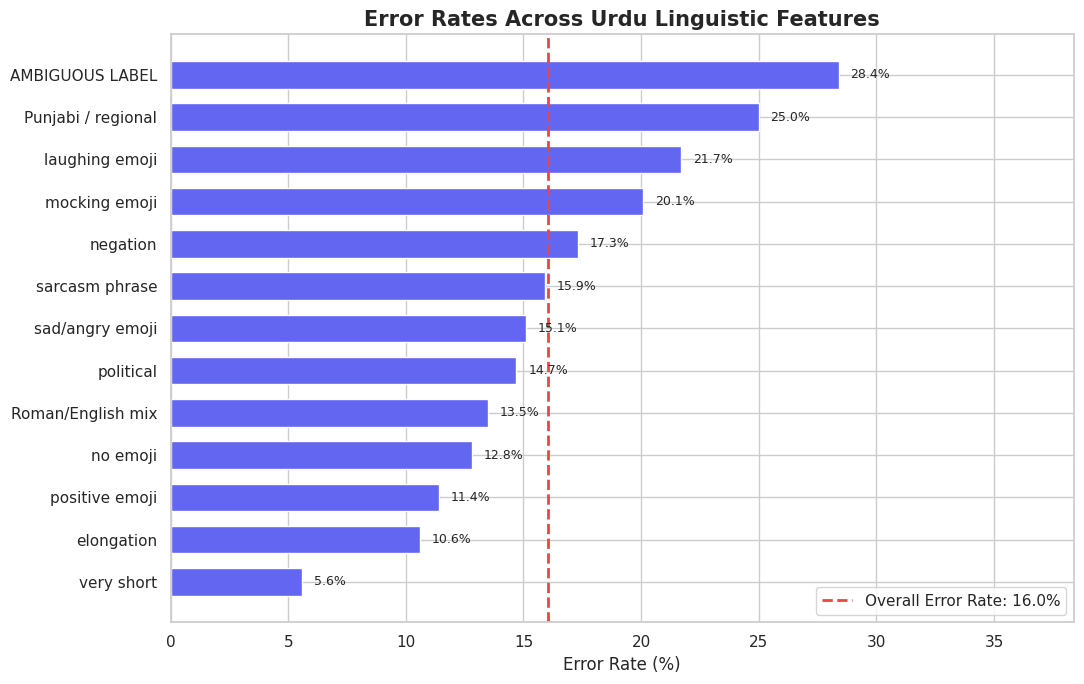

In [168]:

phenomena_df = phenomenon_error_rates(err)

plot_df = phenomena_df.sort_values(
    "error rate %", ascending=True
)

overall_error = 100 * (err["error"] != "correct").mean()

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    plot_df["phenomenon"],
    plot_df["error rate %"],
    color="#6366F1",
    height=0.65
)

ax.axvline(
    overall_error,
    color="#EF4444",
    linestyle="--",
    linewidth=2,
    label=f"Overall Error Rate: {overall_error:.1f}%"
)

ax.set_title(
    "Error Rates Across Urdu Linguistic Features",
    fontsize=15,
    fontweight="bold"
)
ax.set_xlabel("Error Rate (%)")
ax.legend()

for bar in bars:
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}%",
        va="center",
        fontsize=9
    )

ax.set_xlim(0, max(plot_df["error rate %"].max() + 10, 15))
plt.tight_layout()
plt.show()


**False Positives vs False Negatives by Feature**

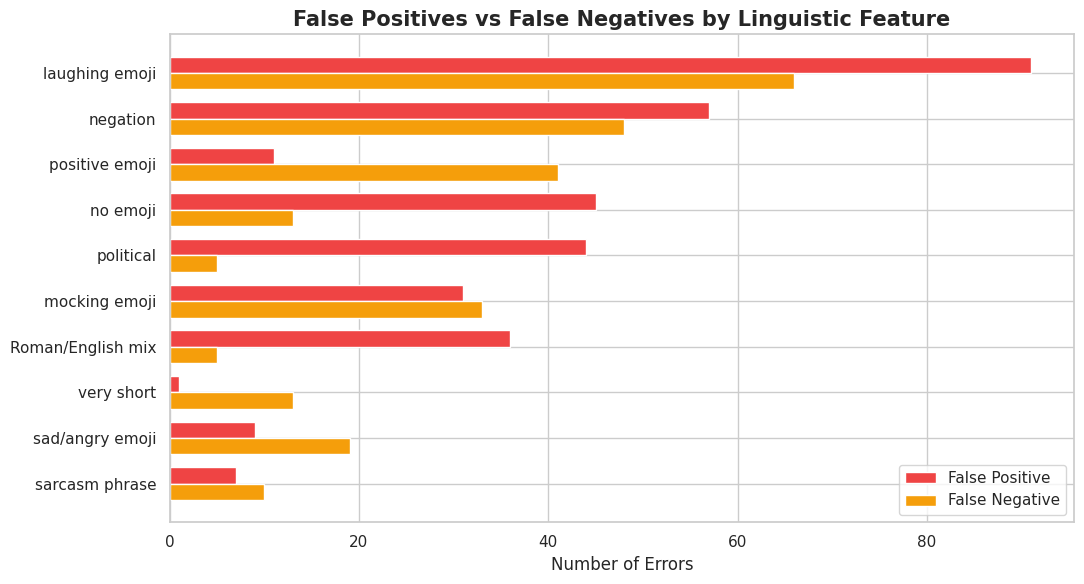

In [169]:

plot_df = phenomena_df.sort_values(
    "posts", ascending=False
).head(10)

fig, ax = plt.subplots(figsize=(11, 6))

y = np.arange(len(plot_df))
bar_height = 0.36

ax.barh(
    y - bar_height / 2,
    plot_df["FP"],
    height=bar_height,
    label="False Positive",
    color="#EF4444"
)

ax.barh(
    y + bar_height / 2,
    plot_df["FN"],
    height=bar_height,
    label="False Negative",
    color="#F59E0B"
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df["phenomenon"])
ax.invert_yaxis()

ax.set_xlabel("Number of Errors")
ax.set_title(
    "False Positives vs False Negatives by Linguistic Feature",
    fontsize=15,
    fontweight="bold"
)
ax.legend()
plt.tight_layout()
plt.show()


### **Error**

Review 15 misclassified posts and briefly explain each error in 1–3 sentences. Focus on possible causes such as missing context, misleading emojis, negation, Urdu idioms, spelling differences, Punjabi expressions, code-mixing, and unclear labels.

Example: A genuine request containing `خان صاحب مہربانی کریو ... 🙏🙏`so 🙏 may be incorrectly classified as sarcastic because the model associates certain words or emojis with sarcasm. This shows how context and language variation can affect predictions.



## Final Results


In [171]:
final_test = results_table("test")
final_test[["model", "accuracy", "precision_0", "recall_0", "f1_0", "precision_1", "recall_1", "f1_1", "macro_f1"]]

,model,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1
0,Ensemble 3 models,0.8435,0.8719,0.8524,0.8620,0.8074,0.8316,0.8193,0.8407
1,Ensemble Twitter XLM-R pair + TF-IDF,0.8396,0.8646,0.8540,0.8592,0.8069,0.8202,0.8135,0.8364
2,Twitter XLM-R pair (text | emoji),0.8308,0.8767,0.8201,0.8475,0.7776,0.8450,0.8099,0.8287
3,Twitter XLM-R single,0.8299,0.8675,0.8301,0.8484,0.7842,0.8295,0.8062,0.8273
4,TF-IDF word+char + SVM,0.8219,0.8262,0.8732,0.8490,0.8154,0.7531,0.7830,0.8160
5,TF-IDF word+char + LR,0.8206,0.8234,0.8747,0.8483,0.8162,0.7479,0.7806,0.8144
6,BiLSTM two branch (fastText),0.8189,0.8306,0.8593,0.8447,0.8017,0.7645,0.7827,0.8137
7,BiLSTM single branch (fastText),0.8171,0.8341,0.8501,0.8420,0.7932,0.7727,0.7828,0.8124
8,TF-IDF word+char + features + LR,0.8149,0.8227,0.8632,0.8425,0.8031,0.7500,0.7756,0.8091
9,TF-IDF char + LR,0.8145,0.8129,0.8786,0.8445,0.8169,0.7283,0.7701,0.8073


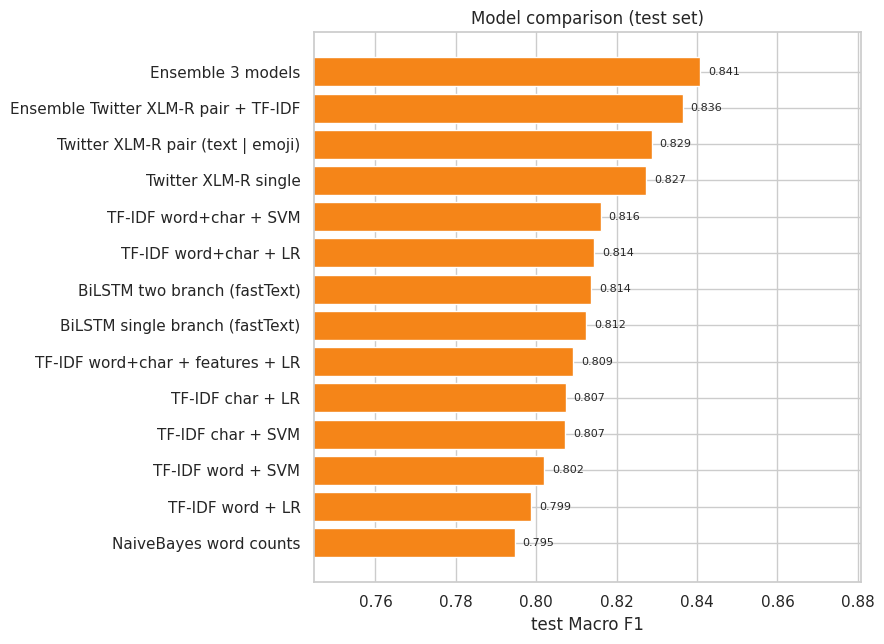

In [172]:
def plot_final(df):
    """Bar chart of test Macro F1 for every model."""
    fig, ax = plt.subplots(figsize=(9, 0.4 * len(df) + 1))
    ax.barh(df["model"], df["macro_f1"], color="#F58518")
    for i, v in enumerate(df["macro_f1"]):
        ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
    ax.set_xlim(df["macro_f1"].min() - 0.05, min(1, df["macro_f1"].max() + 0.04))
    ax.invert_yaxis(); ax.set_xlabel("test Macro F1"); ax.set_title("Model comparison (test set)")
    plt.tight_layout(); plt.show()

plot_final(final_test)

**Model Performance Comparison**

In [175]:

from IPython.display import display

table = final_test[
    ["model", "accuracy", "precision_0", "recall_0",
     "f1_0", "precision_1", "recall_1", "f1_1", "macro_f1"]
].copy()

table = table.sort_values("macro_f1", ascending=False)

display(
    table.style
    .format({c: "{:.4f}" for c in table.columns if c != "model"})
    .background_gradient(subset=["macro_f1"], cmap="Greens")
    .background_gradient(subset=["accuracy"], cmap="Blues")
    .set_properties(**{
        "text-align": "center",
        "padding": "9px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#1E3A8A"),
                ("color", "white"),
                ("padding", "10px")
            ]
        }
    ])
    .hide(axis="index")
)


model,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,macro_f1
Ensemble 3 models,0.8435,0.8719,0.8524,0.8620,0.8074,0.8316,0.8193,0.8407
Ensemble Twitter XLM-R pair + TF-IDF,0.8396,0.8646,0.8540,0.8592,0.8069,0.8202,0.8135,0.8364
Twitter XLM-R pair (text | emoji),0.8308,0.8767,0.8201,0.8475,0.7776,0.8450,0.8099,0.8287
Twitter XLM-R single,0.8299,0.8675,0.8301,0.8484,0.7842,0.8295,0.8062,0.8273
TF-IDF word+char + SVM,0.8219,0.8262,0.8732,0.8490,0.8154,0.7531,0.7830,0.8160
TF-IDF word+char + LR,0.8206,0.8234,0.8747,0.8483,0.8162,0.7479,0.7806,0.8144
BiLSTM two branch (fastText),0.8189,0.8306,0.8593,0.8447,0.8017,0.7645,0.7827,0.8137
BiLSTM single branch (fastText),0.8171,0.8341,0.8501,0.8420,0.7932,0.7727,0.7828,0.8124
TF-IDF word+char + features + LR,0.8149,0.8227,0.8632,0.8425,0.8031,0.7500,0.7756,0.8091
TF-IDF char + LR,0.8145,0.8129,0.8786,0.8445,0.8169,0.7283,0.7701,0.8073


**Final Model Comparison: Accuracy vs Macro-F1**

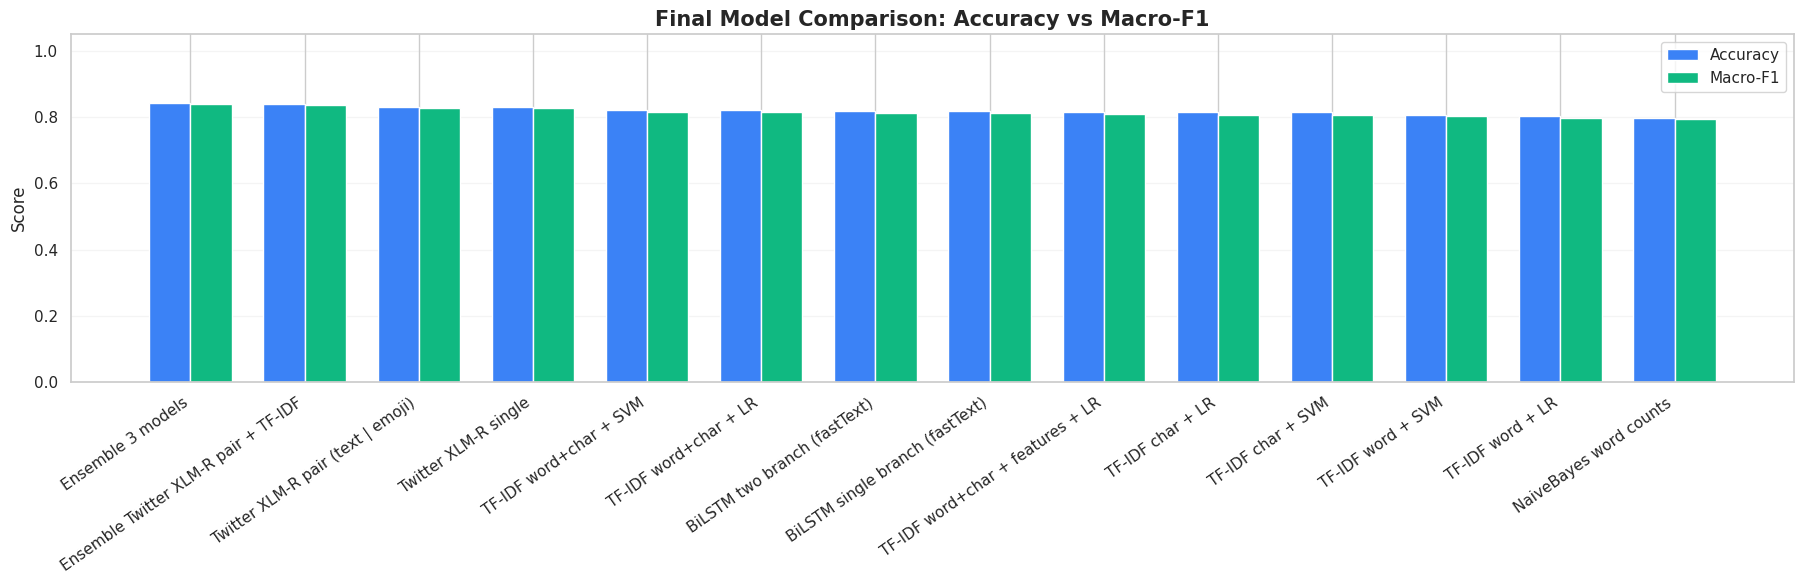

In [176]:
df = final_test.sort_values("macro_f1", ascending=False)

x = np.arange(len(df))
width = 0.36

fig, ax = plt.subplots(figsize=(max(11, len(df) * 1.3), 6))

ax.bar(x - width/2, df["accuracy"], width,
       label="Accuracy", color="#3B82F6")

ax.bar(x + width/2, df["macro_f1"], width,
       label="Macro-F1", color="#10B981")

ax.set_xticks(x)
ax.set_xticklabels(df["model"], rotation=35, ha="right")

ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_title("Final Model Comparison: Accuracy vs Macro-F1",
             fontsize=15, fontweight="bold")

ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


**F1 score Comparison**

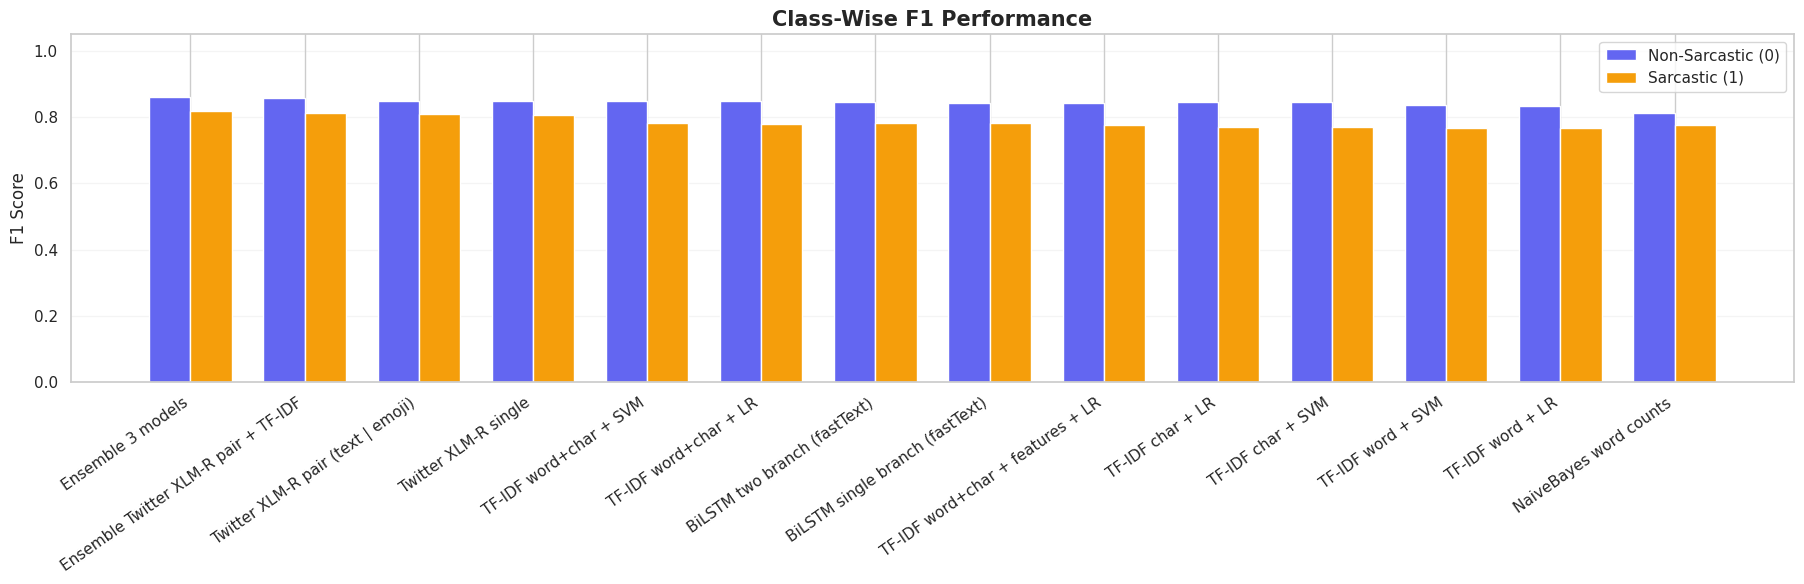

In [177]:
df = final_test.sort_values("macro_f1", ascending=False)

x = np.arange(len(df))
width = 0.36

fig, ax = plt.subplots(figsize=(max(11, len(df) * 1.3), 6))

ax.bar(
    x - width/2, df["f1_0"], width,
    label="Non-Sarcastic (0)", color="#6366F1"
)

ax.bar(
    x + width/2, df["f1_1"], width,
    label="Sarcastic (1)", color="#F59E0B"
)

ax.set_xticks(x)
ax.set_xticklabels(df["model"], rotation=35, ha="right")
ax.set_ylim(0, 1.05)

ax.set_title("Class-Wise F1 Performance",
             fontsize=15, fontweight="bold")
ax.set_ylabel("F1 Score")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


**Performance Heatmap**

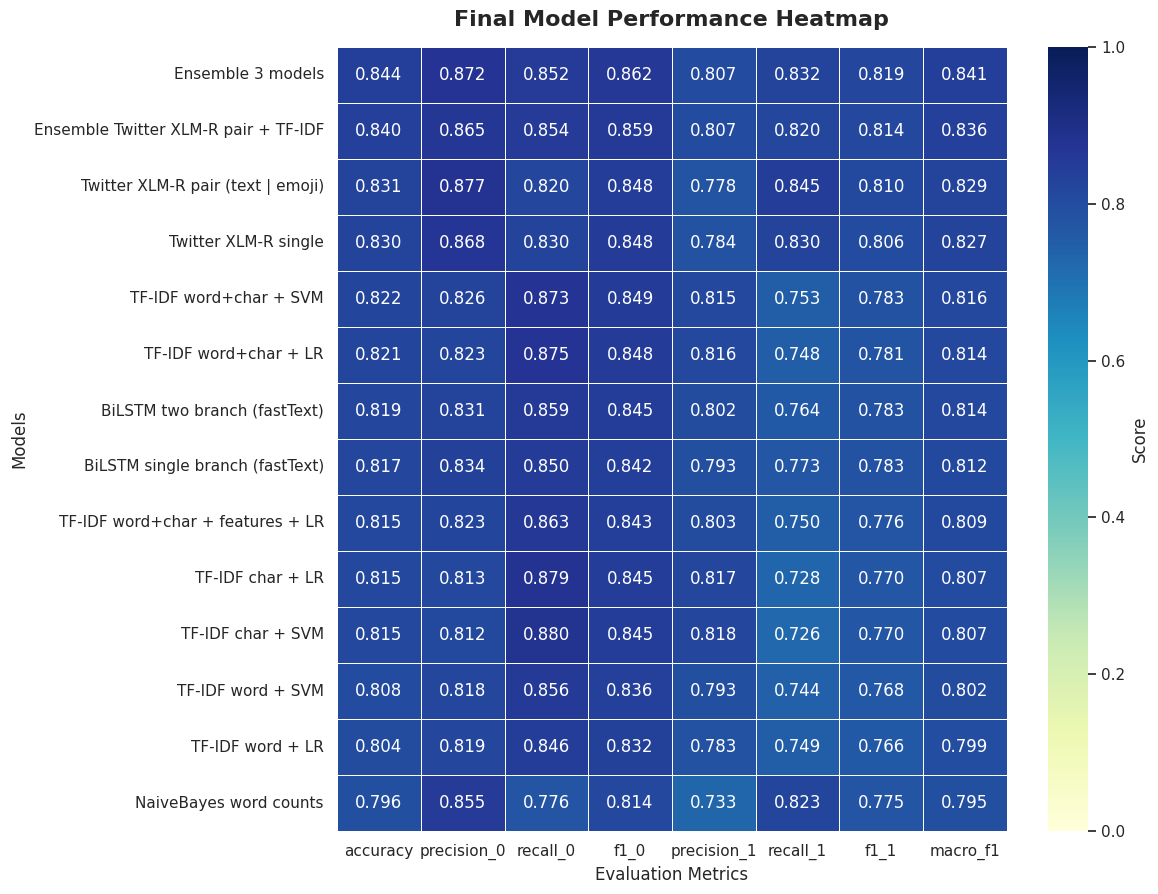

In [178]:
heatmap_df = (
    final_test
    .set_index("model")[
        ["accuracy", "precision_0", "recall_0", "f1_0",
         "precision_1", "recall_1", "f1_1", "macro_f1"]
    ]
    .sort_values("macro_f1", ascending=False)
)

plt.figure(figsize=(12, max(5, len(heatmap_df) * 0.65)))

sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    vmax=1,
    cbar_kws={"label": "Score"}
)

plt.title("Final Model Performance Heatmap",
          fontsize=16, fontweight="bold", pad=15)

plt.xlabel("Evaluation Metrics")
plt.ylabel("Models")
plt.tight_layout()
plt.show()


**Save Models**

In [179]:
def save_everything():
    """Save result tables, predictions, the TF-IDF model and the best transformer."""
    import joblib
    results_table().to_csv(f"{OUT_DIR}/all_results.csv", index=False)
    ablation_df.to_csv(f"{OUT_DIR}/ablations.csv", index=False)
    err.drop(columns=["tags"]).assign(tags=err["tags"].str.join("; ")).to_csv(f"{OUT_DIR}/test_predictions.csv", index=False)
    joblib.dump({"model": best_lr, "vectorizers": best_vecs, "feature_scaler": feat_scaler}, f"{OUT_DIR}/tfidf_lr.joblib")
    torch.save(bilstm_two.state_dict(), f"{OUT_DIR}/bilstm_two_branch.pt")
    best_tx["model"].save_pretrained(f"{OUT_DIR}/best_transformer")
    best_tx["tokenizer"].save_pretrained(f"{OUT_DIR}/best_transformer")
    json.dump({"best_transformer": best_tx_name, "ensemble_weight_transformer": w_ens,
               "lr_C": best_C, "seed": SEED, "tf_cfg": TF_CFG}, open(f"{OUT_DIR}/config.json", "w"), indent=2)
    print("Saved to", OUT_DIR, ":", os.listdir(OUT_DIR))

In [180]:
save_everything()


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved to outputs : ['tfidf_lr.joblib', 'all_results.csv', 'best_transformer', 'config.json', 'ablations.csv', 'test_predictions.csv', 'bilstm_two_branch.pt']


In [181]:
import shutil
from pathlib import Path
source = Path(OUT_DIR)
destination = Path("/content/drive/MyDrive/urdu_sarcasm_outputs")

shutil.copytree(
    source,
    destination,
    dirs_exist_ok=True
)
print("Location:", destination)

Location: /content/drive/MyDrive/urdu_sarcasm_outputs


In [182]:
for file in destination.rglob("*"):
    if file.is_file():
        print(file.relative_to(destination))

test_predictions.csv
ablations.csv
all_results.csv
tfidf_lr.joblib
bilstm_two_branch.pt
config.json
best_transformer/config.json
best_transformer/model.safetensors
best_transformer/tokenizer.json
best_transformer/tokenizer_config.json


 **Check For Reproducibility**

In [183]:
print("Random seed:", SEED)

print("Dataset:", raw_df.shape)

print("Split sizes:")
print({
    "train": len(train_df),
    "validation": len(val_df),
    "test": len(test_df)
})

print("Results rows:", len(RESULTS))

assert not results_table().duplicated(
    subset=["model", "split"]
).any()

assert len(y_test) == len(ens_test_proba)

print("Basic consistency checks passed.")

Random seed: 42
Dataset: (20060, 2)
Split sizes:
{'train': 10588, 'validation': 2269, 'test': 2269}
Results rows: 28
Basic consistency checks passed.
